# How To KudosMaxx: Parts 1 to 3

Part 1: setup and EDA

Part 2: OLS baseline

Part 3: Poisson count models

Part 4: checks and robustness (time-series check, refits, VIF, locked final model)

Part 5: logistic check and synthesis (breakout runs, H1 to H7 table, recommendations)

# Part 1: Data, EDA and time control

## Methodology

**Data:** Eglantine's Strava export, with kudos added by hand. We keep public runs only (178 runs, March 2024 to October 2026 included). Other activity types (hikes, walks, skiing, etc.) and private activities are removed. We use one athlete only, so the results are a case study of a single runner and may not generalize.

**Outcome:** `kudos_count`, the number of kudos per run.

**Predictors:**

| Variable | Type | Group |
|---|---|---|
| Distance | Continuous (km) | Effort |
| Elevation gain | Continuous (m) | Effort |
| Pace | Continuous (min/km) | Effort |
| Achievements | Count | Effort |
| PR rank (best / 2nd / 3rd vs. no PR) | 3 dummies | Effort |
| Media | Yes/no | Visual |
| Custom text (caption or custom title) | Yes/no | Visual |
| Weekend | Yes/no | Timing |
| Days since joining | Continuous (days) | Control for follower growth |

This gives 10 predictor terms + the time control. 178 runs should still be enough for regression, but confidence intervals will be wide for the small categories. The PR groups are small: 16 best efforts, 8 second-best and 21 third-best (vs. 133 runs with no PR). The 2nd-best estimate, based on only 8 runs, will be especially uncertain.

**Coding of the PR variables:**
- `pr_label` = 1 if the run shows a PR or top-3 effort, 0 otherwise.
- `pr_label_rank` = 1 (best), 2 (2nd best), 3 (3rd best), 0 (no PR).
- Because the rank codes are not equally spaced in meaning (and 0 = "no PR" is not "better than best"), the models use **three dummies**: `pr_best`, `pr_2nd`, `pr_3rd`, with "no PR" as the baseline.
- `pr_label` equals the sum of the three dummies, so the models include the dummies **or** `pr_label`, never both. `pr_label` is used for the simple group comparison (H7).

**Hypotheses:**
- **H1 (media):** runs with a photo or video get more kudos, because they stand out in the feed.
- **H2 (achievements):** runs with more achievements get more kudos, since Strava shows the badges on the post.
- **H3 (distance):** longer runs get more kudos, because followers notice the effort.
- **H4 (custom text):** posts with a caption or custom title get more kudos, because they are more personal.
- **H5 (speed):** faster runs get more kudos, because a quick pace signals performance.
- **H6 (weekend):** weekend runs get more kudos, since followers have more free time to scroll.
- **H7 (PR):** runs with a PR or top-3 effort get more kudos, because the PR is displayed on the post and signals a personal milestone. If so, we also expect best efforts to earn more than 3rd-best efforts (the data support this for 3rd-best runs only).

**Models:**
- OLS as a simple baseline, then Poisson regression since kudos are counts. If kudos are overdispersed, we check this with the Pearson dispersion ratio and report robust standard errors.
- Four nested models: **A** time only; **B** time + effort (distance, elevation, pace, achievements, PR dummies); **C** time + presentation (media, custom text); **D** full model (all of the above + weekend). D is the main model for interpreting effects. Comparing B and C against A (likelihood ratio tests, AIC) shows whether effort or presentation explains more.
- Time control: start with linear days since joining, then days + days squared, then quarter dummies if neither fits well.

**Collinearity between achievements and PR:** PRs are one kind of achievement, so `achievements_count` and the PR variables are correlated. They still measure different things: achievements is a count that is usually much higher and can occur without a PR, while the PR dummies capture whether a top-3 personal effort was shown. We keep both, check their correlation and variance inflation factors (VIF) once the models are fitted, and interpret their separate effects with care.

**Diagnostics:** Residual plots, influential runs, residual autocorrelation (ACF, Ljung-Box, Durbin-Watson), and refits with alternative time controls.

## Load and clean the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

strava = pd.read_excel("strava_activities.xlsx")

In [ ]:
strava.head()

,activity_id,url,kudos_count,achievements_count,private,official_race,pr_label,pr_label_rank,pr_label_discipline,activity_date,...,average_grade_adjusted_pace,total_cycles,recovery,with_pet,with_kid,media,n_photos,n_videos,n_media,has_media
0,10879539215,https://www.strava.com/activities/10879539215,3,24,0,0,1,1.0,NaN,2024-03-03 09:47:35,...,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,False
1,10994038398,https://www.strava.com/activities/10994038398,2,6,0,0,1,1.0,NaN,2024-03-19 16:05:59,...,NaN,NaN,NaN,NaN,NaN,media/8186551D-3D27-4632-9854-F01842941611.jpg,1,0,1,True
2,11036523226,https://www.strava.com/activities/11036523226,2,6,0,0,1,1.0,NaN,2024-03-25 17:59:44,...,NaN,NaN,NaN,NaN,NaN,media/B26A3C23-8621-4D98-A236-A97941020168.jpg,1,0,1,True
3,11117201162,https://www.strava.com/activities/11117201162,5,1,0,0,0,0.0,0.0,2024-04-06 08:54:10,...,2.317,NaN,NaN,NaN,NaN,media/664D1CC7-8BD6-46B1-A983-4FD573B7D52B.jpg,1,0,1,True
4,11135903078,https://www.strava.com/activities/11135903078,3,4,0,0,1,3.0,NaN,2024-04-08 16:53:59,...,2.547,NaN,NaN,NaN,NaN,media/7AA86FFF-C502-40E7-BEC6-B4620330D73A.jpg...,2,0,2,True


In [ ]:
strava.describe()

,activity_id,kudos_count,achievements_count,private,official_race,pr_label,pr_label_rank,pr_label_discipline,activity_date,bike_weight,...,total_steps,carbon_saved,average_grade_adjusted_pace,total_cycles,recovery,with_pet,with_kid,n_photos,n_videos,n_media
count,2.460000e+02,246.000000,246.000000,246.000000,246.000000,246.000000,245.000000,209.000000,246,1.0,...,200.000000,129.0,190.000000,23.000000,45.0,29.0,24.0,246.000000,246.000000,246.000000
mean,1.561022e+10,8.768293,4.971545,0.081301,0.028455,0.195122,0.400000,0.559569,2025-08-04 23:59:39.337398272,9.0,...,7674.600000,0.0,2.536937,11750.695652,0.0,0.0,0.0,0.967480,0.040650,1.008130
min,1.087954e+10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2024-03-03 09:47:35,9.0,...,168.000000,0.0,1.355000,1662.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
25%,1.309568e+10,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2024-12-11 21:41:06.249999872,9.0,...,4552.000000,0.0,2.412500,6047.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
50%,1.531773e+10,9.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2025-08-02 09:30:54,9.0,...,6586.000000,0.0,2.518000,10156.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000
75%,1.792980e+10,12.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2026-03-31 15:54:28,9.0,...,9808.000000,0.0,2.654000,16062.000000,0.0,0.0,0.0,2.000000,0.000000,2.000000
max,2.082138e+10,29.000000,51.000000,1.000000,1.000000,1.000000,3.000000,21.000000,2026-11-01 18:19:25,9.0,...,27180.000000,0.0,3.596000,27180.000000,0.0,0.0,0.0,7.000000,2.000000,7.000000
std,2.896123e+09,4.701625,8.018550,0.273854,0.166609,0.397102,0.911673,2.712029,NaN,NaN,...,4553.425261,0.0,0.244401,7221.914821,0.0,0.0,0.0,1.495217,0.217533,1.541247


In [ ]:
# full export: activity types before filtering
print("All activities:", len(strava))
print(strava["activity_type"].value_counts())

# dropping all private activities
strava = strava[strava["private"] == 0]
print("\nPublic activities:", len(strava))

# keeping runs only (new DataFrame used for the rest of the analysis)
runs = strava[strava["activity_type"].str.strip() == "Run"].copy()
print("Public runs:", len(runs))

All activities: 246
activity_type
Run                197
Hike                26
Walk                10
Alpine Ski           6
Ride                 3
Swim                 2
Rowing               1
Weight Training      1
Name: count, dtype: int64

Public activities: 226
Public runs: 179


In [ ]:
#converting string activity date to date time
runs["activity_date"] = pd.to_datetime(runs["activity_date"], errors="coerce")

In [ ]:
# keep runs up to the end of October 2026 (November runs may still be collecting kudos)
cutoff = pd.Timestamp("2026-10-31 23:59:59")
recent = runs[runs["activity_date"] > cutoff]
print("Runs removed (after cutoff):", len(recent))
display(recent[["activity_name", "activity_date", "kudos_count"]])

runs = runs[runs["activity_date"] <= cutoff].copy()
print("Runs kept:", len(runs))

Runs removed (after cutoff): 1


,activity_name,activity_date,kudos_count
245,Afternoon Run,2026-11-01 18:19:25,8


Runs kept: 178


In [ ]:
# changing units + creating derived variables
runs["distance_km"] = runs["distance"] / 1000
runs["moving_min"]  = runs["moving_time"] / 60
runs["pace_min_per_km"] = runs["moving_min"] / runs["distance_km"].replace(0, np.nan)
runs["hour"]    = runs["activity_date"].dt.hour          # UTC hour
runs["weekday"] = runs["activity_date"].dt.day_name()
runs["has_description"] = runs["activity_description"].notna()

In [ ]:
# looking at size and missing values
print(runs.shape)
print("\nShare missing (top 20):\n", runs.isna().mean().sort_values(ascending=False).head(20).round(2))

(178, 81)

Share missing (top 20):
 number_of_runs               1.00
total_cycles                 1.00
bike_weight                  1.00
perceived_exertion           0.99
perceived_relative_effort    0.99
average_watts                0.99
weather_temperature          0.96
weather_visibility           0.96
cloud_cover                  0.96
precipitation_type           0.96
precipitation_probability    0.96
weather_condition            0.96
weather_observation_time     0.96
dewpoint                     0.96
humidity                     0.96
weather_pressure             0.96
wind_speed                   0.96
wind_gust                    0.96
wind_bearing                 0.96
precipitation_intensity      0.96
dtype: float64


In [ ]:
# creating categorical / binary variables

# 1 if the activity was on a Saturday or Sunday, 0 otherwise
runs["is_weekend"] = runs["weekday"].isin(["Saturday", "Sunday"]).astype(int)

# converting has media from boolean to binary 0/1
runs["has_media"] = runs["has_media"].astype(int)

default_titles = ["morning run", "lunch run", "afternoon run", "evening run"]

# 1 if the title is not one of Strava's default names
title = runs["activity_name"].fillna("").str.strip().str.lower()
runs["has_custom_title"] = (~title.isin(default_titles) & (title != "")).astype(int)

# 1 if there is a non-empty caption (description)
caption = runs["activity_description"].fillna("").str.strip()
runs["has_caption"] = (caption != "").astype(int)

# 1 if the activity has a custom title, a caption, or both
runs["has_custom_text"] = ((runs["has_custom_title"] == 1) | (runs["has_caption"] == 1)).astype(int)

# 1 if the run earned at least one achievement
runs["has_achievements"] = (runs["achievements_count"] > 0).astype(int)

# 1 if the run is 10 km or longer
runs["is_long"] = (runs["distance_km"] >= 10).astype(int)

# 1 if faster than the median pace (a lower min/km means faster)
median_pace = runs["pace_min_per_km"].median()
runs["is_fast"] = np.where(runs["pace_min_per_km"].isna(), np.nan,
                           (runs["pace_min_per_km"] < median_pace).astype(float))
mins = int(median_pace)
secs = round((median_pace - mins) * 60)
print(f"Median pace: {mins}:{secs:02d} min/km")

# PR dummies (baseline = no PR); pr_label_rank: 1 = best, 2 = 2nd best, 3 = 3rd best, 0 = no PR
runs["pr_best"] = (runs["pr_label_rank"] == 1).astype(int)
runs["pr_2nd"]  = (runs["pr_label_rank"] == 2).astype(int)
runs["pr_3rd"]  = (runs["pr_label_rank"] == 3).astype(int)

# consistency check: pr_label should equal 1 exactly when there is a rank
mismatch = runs[runs["pr_label"] != (runs["pr_best"] + runs["pr_2nd"] + runs["pr_3rd"])]
print("Runs where pr_label and pr_label_rank disagree:", len(mismatch))

Median pace: 6:39 min/km
Runs where pr_label and pr_label_rank disagree: 0


In [ ]:
#Numeric summary for runs
num_vars = ["kudos_count", "achievements_count", "pr_label", "distance_km", "moving_min", "pace_min_per_km",
            "elevation_gain", "average_heart_rate", "max_heart_rate", "relative_effort",
            "n_photos", "n_videos", "n_media"]
desc = runs[num_vars].describe().T
desc["median"] = runs[num_vars].median()
desc["skew"]   = runs[num_vars].skew()
display(desc.round(2))

,count,mean,std,min,25%,50%,75%,max,median,skew
kudos_count,178.0,9.89,4.09,1.00,7.00,9.50,12.00,29.00,9.50,1.04
achievements_count,178.0,6.37,8.85,0.00,0.25,3.50,8.00,51.00,3.50,2.54
pr_label,178.0,0.25,0.44,0.00,0.00,0.00,0.75,1.00,0.00,1.15
distance_km,178.0,7.58,3.54,0.86,5.03,6.96,10.01,21.65,6.96,1.25
moving_min,178.0,50.94,24.56,4.63,32.78,45.72,64.64,143.15,45.72,1.11
pace_min_per_km,178.0,6.68,0.56,4.97,6.34,6.64,6.99,9.24,6.64,0.72
elevation_gain,178.0,43.68,64.20,0.00,7.22,17.55,48.00,376.80,17.55,2.42
average_heart_rate,73.0,173.11,6.41,159.00,171.00,173.00,177.00,185.00,173.00,-0.31
max_heart_rate,73.0,186.23,5.08,175.00,183.00,187.00,190.00,198.00,187.00,-0.23
relative_effort,73.0,174.27,118.87,31.00,96.00,139.00,237.00,602.00,139.00,1.59


In [ ]:
for col in ["has_media", "official_race", "has_description", "is_weekend", "has_custom_text",
            "has_achievements", "is_long", "is_fast", "pr_label", "pr_label_rank"]:
    print(f"\n{col}:\n", runs[col].value_counts(dropna=False))


has_media:
 has_media
0    113
1     65
Name: count, dtype: int64

official_race:
 official_race
0    172
1      6
Name: count, dtype: int64

has_description:
 has_description
True     98
False    80
Name: count, dtype: int64

is_weekend:
 is_weekend
0    116
1     62
Name: count, dtype: int64

has_custom_text:
 has_custom_text
1    125
0     53
Name: count, dtype: int64

has_achievements:
 has_achievements
1    133
0     45
Name: count, dtype: int64

is_long:
 is_long
0    130
1     48
Name: count, dtype: int64

is_fast:
 is_fast
0.0    89
1.0    89
Name: count, dtype: int64

pr_label:
 pr_label
0    133
1     45
Name: count, dtype: int64

pr_label_rank:
 pr_label_rank
0.0    133
3.0     21
1.0     16
2.0      8
Name: count, dtype: int64


In [ ]:
#Kudos by group
for col in ["has_media", "official_race", "is_weekend", "has_custom_text", "pr_label", "pr_label_rank"]:
    display(runs.groupby(col)["kudos_count"].agg(["count", "mean", "median", "std"]).round(2))

,count,mean,median,std
has_media,,,,
0,113,9.02,9.0,3.16
1,65,11.40,12.0,5.01


,count,mean,median,std
official_race,,,,
0,172,9.55,9.0,3.55
1,6,19.67,18.5,6.50


,count,mean,median,std
is_weekend,,,,
0,116,9.08,9.0,3.36
1,62,11.40,11.0,4.85


,count,mean,median,std
has_custom_text,,,,
0,53,9.00,8.0,3.82
1,125,10.26,10.0,4.15


,count,mean,median,std
pr_label,,,,
0,133,9.68,9.0,3.38
1,45,10.49,10.0,5.69


,count,mean,median,std
pr_label_rank,,,,
0.0,133,9.68,9.0,3.38
1.0,16,12.12,12.5,7.04
2.0,8,12.50,11.0,6.35
3.0,21,8.48,8.0,3.46


## Preliminary hypothesis tests (Welch t-tests, no controls)

In [ ]:
#computing averages, counts and p value for each hypothesis

from scipy import stats

comparisons = {
    "H1 (Media)":        "has_media",
    "H2 (Achievements)": "has_achievements",
    "H3 (Distance)":     "is_long",
    "H4 (Custom text)":  "has_custom_text",
    "H5 (Speed)":        "is_fast",
    "H6 (Weekend)":      "is_weekend",
    "H7 (PR)":           "pr_label",
}

rows = []
for hypothesis, col in comparisons.items():
    data = runs.dropna(subset=[col])
    yes = data.loc[data[col] == 1, "kudos_count"]
    no  = data.loc[data[col] == 0, "kudos_count"]

    # skip the test if one group is too small to compare
    if len(yes) < 2 or len(no) < 2:
        p_value = np.nan
    else:
        p_value = stats.ttest_ind(yes, no, equal_var=False).pvalue

    rows.append({
        "hypothesis": hypothesis,
        "n_yes": len(yes),
        "n_no": len(no),
        "mean_kudos_yes": yes.mean(),
        "mean_kudos_no": no.mean(),
        "p_value": p_value,
    })

summary = pd.DataFrame(rows)
display(summary.round(3))

,hypothesis,n_yes,n_no,mean_kudos_yes,mean_kudos_no,p_value
0,H1 (Media),65,113,11.400,9.018,0.001
1,H2 (Achievements),133,45,9.797,10.156,0.619
2,H3 (Distance),48,130,12.396,8.962,0.000
3,H4 (Custom text),125,53,10.264,9.000,0.052
4,H5 (Speed),89,89,9.944,9.831,0.855
5,H6 (Weekend),62,116,11.403,9.078,0.001
6,H7 (PR),45,133,10.489,9.684,0.374


In [ ]:
#Computing correlations with kudos (runs only, PR dummies included)
corr_vars = num_vars + ["pr_best", "pr_2nd", "pr_3rd"]
corr = runs[corr_vars].corr()
print(corr["kudos_count"].sort_values(ascending=False).round(2))

# overlap between achievements and PR (see methodology)
print("\nCorrelation achievements_count vs pr_label:",
      round(runs["achievements_count"].corr(runs["pr_label"]), 2))

kudos_count           1.00
relative_effort       0.72
distance_km           0.52
moving_min            0.48
average_heart_rate    0.47
max_heart_rate        0.36
n_photos              0.33
n_media               0.33
elevation_gain        0.26
pr_best               0.17
pr_2nd                0.14
pr_label              0.09
achievements_count    0.07
n_videos             -0.02
pace_min_per_km      -0.03
pr_3rd               -0.13
Name: kudos_count, dtype: float64

Correlation achievements_count vs pr_label: 0.42


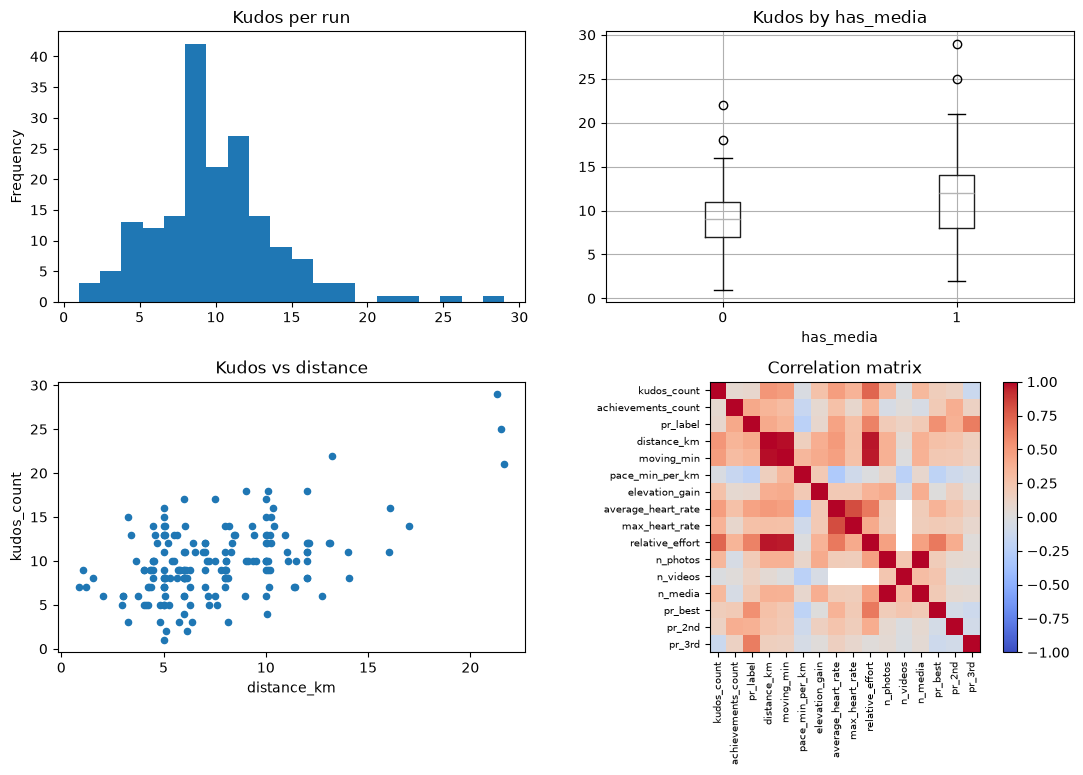

In [ ]:
# creating few plots (runs only)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
runs["kudos_count"].plot.hist(bins=20, ax=axes[0, 0], title="Kudos per run")
runs.boxplot(column="kudos_count", by="has_media", ax=axes[0, 1]); axes[0, 1].set_title("Kudos by has_media")
runs.plot.scatter(x="distance_km", y="kudos_count", ax=axes[1, 0], title="Kudos vs distance")
im = axes[1, 1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1, 1].set_xticks(range(len(corr_vars)), corr_vars, rotation=90, fontsize=7)
axes[1, 1].set_yticks(range(len(corr_vars)), corr_vars, fontsize=7)
axes[1, 1].set_title("Correlation matrix"); fig.colorbar(im, ax=axes[1, 1])
plt.suptitle(""); plt.tight_layout(); plt.show()

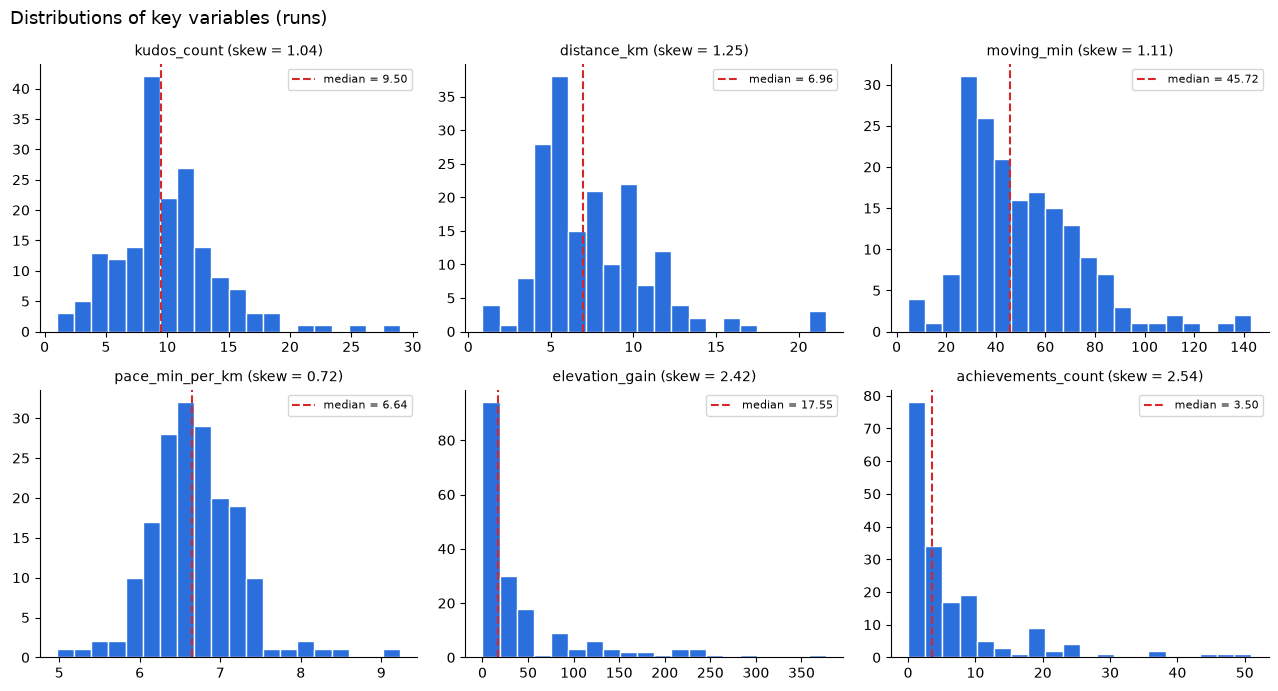

In [ ]:
# distributions of the main variables (runs only)
dist_vars = ["kudos_count", "distance_km", "moving_min", "pace_min_per_km",
             "elevation_gain", "achievements_count"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, dist_vars):
    data = runs[col].dropna()
    ax.hist(data, bins=20, color="#2a6fdb", edgecolor="white")
    ax.axvline(data.median(), color="#d62728", linestyle="--", linewidth=1.5,
               label=f"median = {data.median():.2f}")
    ax.set_title(f"{col} (skew = {data.skew():.2f})", fontsize=10)
    ax.legend(fontsize=8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

plt.suptitle("Distributions of key variables (runs)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
k = runs["kudos_count"]
print("Mean:     ", round(k.mean(), 2))
print("Variance: ", round(k.var(), 2))
print("Var/Mean: ", round(k.var() / k.mean(), 2))

Mean:      9.89
Variance:  16.7
Var/Mean:  1.69


### Distributions (runs only)

- **Kudos:** moderately right-skewed (skew 0.99), median 9, range 0–29. Only 4 runs get 20+ kudos: 3 of them are official half marathons (Semi de Lille, 29; Semi de Montreal 2026, 25; Demi marathon de Mont Tremblant, 21), and the fourth is a 13 km "Lunch Run" with 22 kudos. Across all 6 official races, the mean is 17.2 kudos, against 9.6 for other runs. The variance (≈17) is about 1.7 times the mean (≈9.8), a first sign of overdispersion, so a Poisson model may not fit well on its own. This will be checked with the Pearson dispersion ratio after fitting the Poisson model.
- **Distance:** right-skewed (skew 1.25), median 6.9 km, with most runs between 4 and 12 km and peaks around 5 and 10 km (common round distances). A few long runs (~21 km) form the tail.
- **Moving time:** mirrors distance (skew 1.11, median 45.6 min), since it is mostly distance × pace. It is not used as a predictor, to avoid redundancy with distance and pace.
- **Pace:** roughly symmetric (skew 0.71), median 6.64 min/km (≈ 6:38 per km), mostly between 6 and 7.5 min/km, with one slow run above 9 min/km.
- **Elevation gain:** strongly right-skewed (skew 2.43). Most runs are nearly flat (median 17.5 m), but a few exceed 200 m.
- **Achievements:** strongly right-skewed (skew 2.55), median 3, with most runs between 0 and 10 and a tail up to about 50.

Because elevation gain and achievements are strongly skewed, a few extreme runs could have large influence in the regression. We will consider a log(x + 1) transformation for these two variables and check influential observations after fitting the models.

In [ ]:
#checking whether races are the outliers
print(runs.loc[runs["kudos_count"] >= 20, ["activity_name", "distance_km", "official_race", "kudos_count"]])

                       activity_name  distance_km  official_race  kudos_count
92                     Semi de Lille      21.2950              1           29
133                        Lunch Run      13.2511              0           22
217  Demi marathon de Mont Tremblant      21.6521              1           21
240            Semi de Montreal 2026      21.5041              1           25


Three of the four runs with 20 or more kudos are half marathons.

### Kudos by PR rank
Strava shows a badge when a run contains a personal record (best effort) or a 2nd/3rd-best effort. This box plot compares kudos across these groups to explore H7 before running any models.

- Runs with a PR or 2nd best effort received higher kudos than runs without (median 12 and 11 vs 9). However, runs with no PR have a median of 9 kudos, one more than 3rd-best runs (median 8)..
- Among PR runs, best efforts get more kudos than 3rd-best runs (mean 11.2 vs 8.5), but not more than 2nd-best runs (mean 12.5).

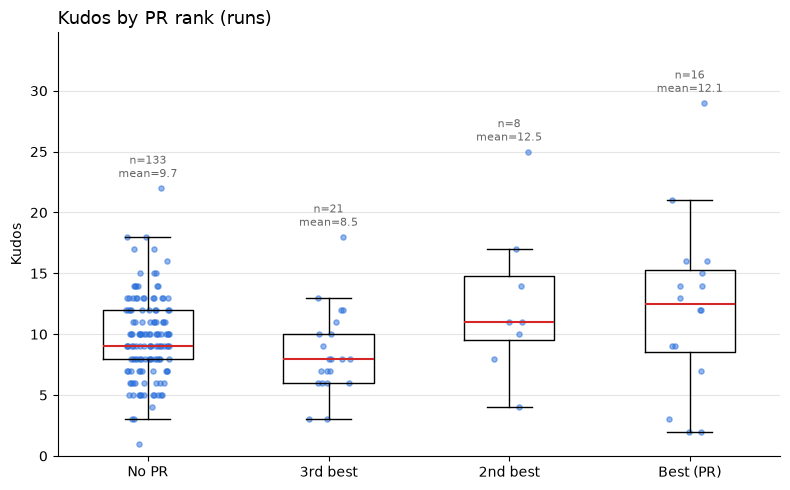

In [ ]:
# kudos by PR rank (0 = no PR, 3 = 3rd best, 2 = 2nd best, 1 = best)
order  = [0, 3, 2, 1]
labels = ["No PR", "3rd best", "2nd best", "Best (PR)"]
groups = [runs.loc[runs["pr_label_rank"] == r, "kudos_count"] for r in order]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(groups, widths=0.5, showfliers=False,
           medianprops=dict(color="#d62728", linewidth=1.5))

# individual runs as jittered points (groups are small, so show the raw data)
rng = np.random.default_rng(67)
for i, g in enumerate(groups, start=1):
    x = i + rng.uniform(-0.12, 0.12, len(g))
    ax.scatter(x, g, s=14, alpha=0.5, color="#2a6fdb")
    ax.annotate(f"n={len(g)}\nmean={g.mean():.1f}", (i, g.max() if len(g) else 0),
                textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color="#666666")

ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_ylabel("Kudos")
ax.set_title("Kudos by PR rank (runs)", loc="left", fontsize=13)
ax.set_ylim(bottom=0, top=runs["kudos_count"].max() * 1.2)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
pr_table = (runs.groupby("pr_label_rank")["kudos_count"]
                .agg(["count", "mean", "median", "std"])
                .reindex(order))
pr_table.index = labels
display(pr_table.round(2))

,count,mean,median,std
No PR,133,9.68,9.0,3.38
3rd best,21,8.48,8.0,3.46
2nd best,8,12.50,11.0,6.35
Best (PR),16,12.12,12.5,7.04


## Monthly kudos series and decomposition
Average kudos per run by month, to see the long-term trend (follower growth) and any seasonal pattern before choosing a time control.

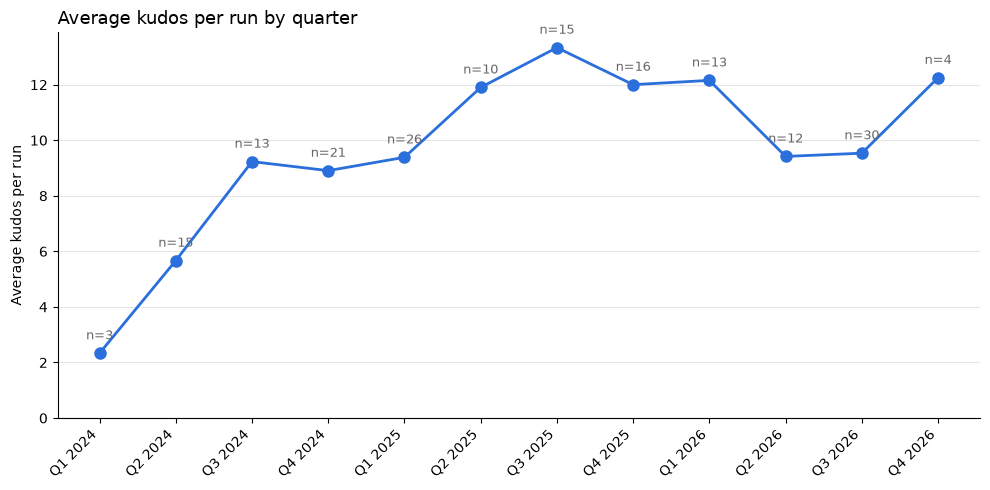

,quarter,mean,count
0,2024Q1,2.33,3
1,2024Q2,5.67,15
2,2024Q3,9.23,13
3,2024Q4,8.90,21
4,2025Q1,9.38,26
5,2025Q2,11.90,10
6,2025Q3,13.33,15
7,2025Q4,12.00,16
8,2026Q1,12.15,13
9,2026Q2,9.42,12


In [ ]:
# average kudos and number of runs per quarter
runs["quarter"] = runs["activity_date"].dt.to_period("Q")
quarterly = runs.groupby("quarter")["kudos_count"].agg(["mean", "count"]).reset_index()

# labels like "Q1 2024" instead of "2024Q1"
labels = quarterly["quarter"].astype(str).str.replace(r"(\d{4})Q(\d)", r"Q\2 \1", regex=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(labels, quarterly["mean"], color="#2a6fdb", linewidth=2, marker="o", markersize=8)

# show the number of runs above each point
for i, (avg, n) in enumerate(zip(quarterly["mean"], quarterly["count"])):
    ax.annotate(f"n={n}", (i, avg), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, color="#666666")

ax.set_title("Average kudos per run by quarter", loc="left", fontsize=13)
ax.set_ylabel("Average kudos per run")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(quarterly.round(2))

Number of months: 32
Months with no runs: none


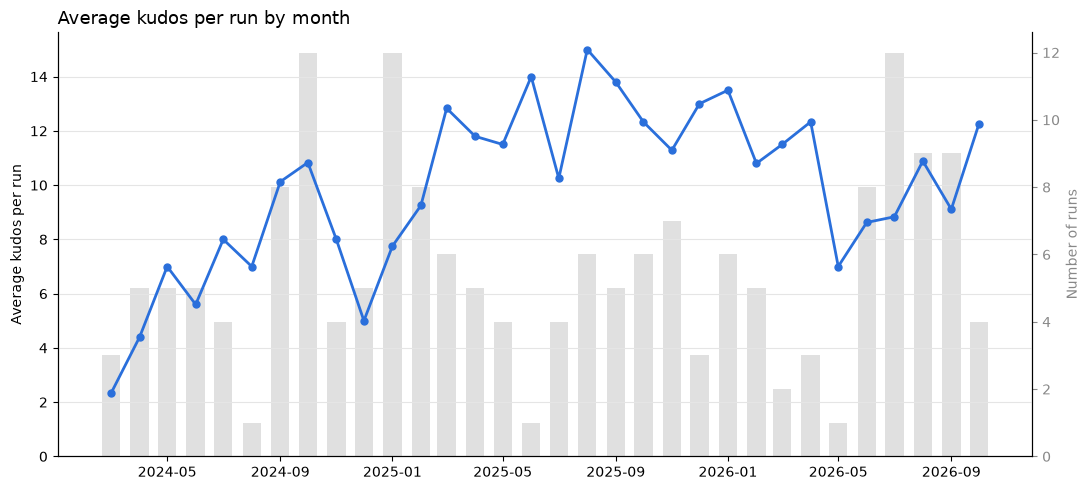

,mean,count
activity_date,,
2024-03-01,2.33,3
2024-04-01,4.40,5
2024-05-01,7.00,5
2024-06-01,5.60,5
2024-07-01,8.00,4
2024-08-01,7.00,1
2024-09-01,10.12,8
2024-10-01,10.83,12
2024-11-01,8.00,4


In [ ]:
# average kudos per run and number of runs per month
monthly = (runs.dropna(subset=["activity_date"])
               .set_index("activity_date")
               .resample("MS")["kudos_count"]
               .agg(["mean", "count"]))

# months with no runs have mean = NaN
empty_months = monthly[monthly["count"] == 0].index.strftime("%b %Y").tolist()
print("Number of months:", len(monthly))
print("Months with no runs:", empty_months if empty_months else "none")

fig, ax1 = plt.subplots(figsize=(11, 5))

# bars = number of runs (right axis), line = average kudos (left axis)
ax2 = ax1.twinx()
ax2.bar(monthly.index, monthly["count"], width=20, color="#cccccc", alpha=0.6)
ax2.set_ylabel("Number of runs", color="#888888")
ax2.tick_params(axis="y", colors="#888888")

ax1.plot(monthly.index, monthly["mean"], color="#2a6fdb", linewidth=2, marker="o", markersize=5)
ax1.set_ylabel("Average kudos per run")
ax1.set_ylim(bottom=0)
ax1.set_zorder(ax2.get_zorder() + 1)   # draw the line above the bars
ax1.patch.set_visible(False)

ax1.set_title("Average kudos per run by month", loc="left", fontsize=13)
ax1.grid(axis="y", color="#e5e5e5", linewidth=0.8)
for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

display(monthly.round(2))

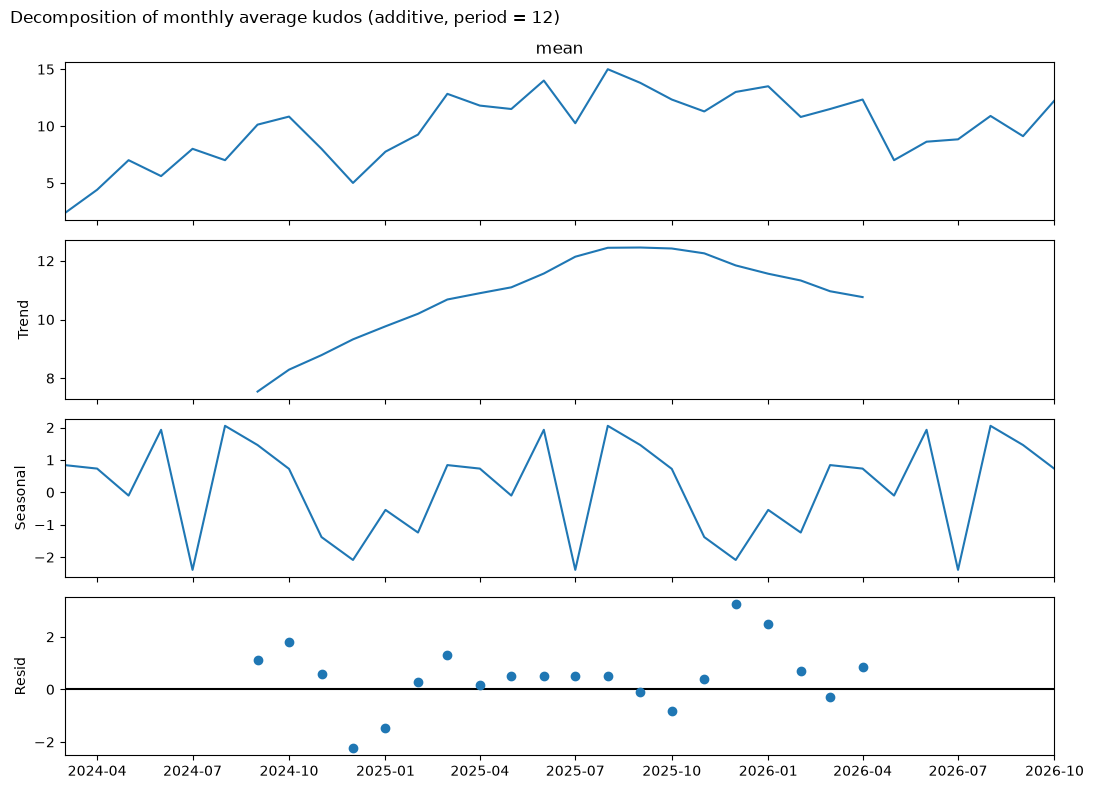

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# decomposition needs a complete series, so fill empty months by linear interpolation
series = monthly["mean"].interpolate()

decomp = seasonal_decompose(series, model="additive", period=12)

fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Decomposition of monthly average kudos (additive, period = 12)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Interpretation of the decomposition

- **Trend:** average kudos rise steadily from about 7.5 (autumn 2024) to a peak of about 12.3 (summer–autumn 2025), then decline to about 10.5 by spring 2026. This inverted-U shape matches follower growth followed by a flattening or decline in engagement. A linear time trend cannot capture a rise followed by a decline, which suggests a **quadratic time control** (days + days²). We will confirm this choice by comparing linear, quadratic and quarter-dummy versions of the time-only model (Model A) before adding any other predictors.
- **Seasonality:** the seasonal component ranges from about −2 to +2 kudos, but it alternates sharply from one month to the next rather than following a smooth summer/winter pattern. With only about 2.5 years of data, this pattern is estimated from very few cycles and most likely reflects noise (e.g., months with few runs or with a race) rather than true seasonality. We therefore do not add month or season variables to the models.
- **Residuals:** mostly within ±2.5 kudos with no clear pattern. The largest deviations are in December 2024 (about −2.5) and December 2025 (about +3). These months are not unusually thin (5 and 3 runs), so the spikes are not explained by small samples. The months that really have very few runs are August 2024, June 2025 and May 2026 (1 run each); their monthly average is just one run’s kudos count, which adds noise to the series and to the decomposition.
- **Limitation:** the trend is a 12-month centred moving average, so it is not defined for the first and last 6 months of the series.

## Controlling for follower growth

In [ ]:
# time since first run (control for follower growth)
first_run = runs["activity_date"].min()
print("First run:", first_run.date())

runs["days_since_first_run"] = (runs["activity_date"] - first_run).dt.days

# centred time in years, to keep the linear and squared terms from being almost identical
mean_days = runs["days_since_first_run"].mean()
runs["t"]    = (runs["days_since_first_run"] - mean_days) / 365
runs["t_sq"] = runs["t"] ** 2

print(runs[["days_since_first_run", "t", "t_sq"]].describe().round(2))

print("\nCorr(days, days²) raw:", round(runs["days_since_first_run"].corr(runs["days_since_first_run"] ** 2), 2))
print("Corr(t, t²) centred:  ", round(runs["t"].corr(runs["t_sq"]), 2))

First run: 2024-03-03
       days_since_first_run       t    t_sq
count                178.00  178.00  178.00
mean                 501.19   -0.00    0.61
std                  285.31    0.78    0.52
min                    0.00   -1.37    0.00
25%                  263.00   -0.65    0.15
50%                  489.00   -0.03    0.47
75%                  768.50    0.73    1.02
max                  970.00    1.28    1.89

Corr(days, days²) raw: 0.97
Corr(t, t²) centred:   0.08


- Time is measured as days since the first run which is also the day the user joined the app (3 March 2024), ranging from 0 to 970 days. It stands in for follower growth, since follower counts at each run are unknown.
- For the quadratic time control, time was centred at its mean and converted to years: `t = (days − mean) / 365`, and `t_sq = t²`.
- Centring reduces the correlation between the linear and squared terms from 0.97 to 0.08, which keeps their coefficients stable. It does not change the model's fit.

## Choice of time control
We compare three ways of controlling for follower growth in a time-only model, before adding any run characteristics: a linear trend, a quadratic trend (centred years), and quarter dummies. Each is fitted as a Poisson model.

In [ ]:
import statsmodels.formula.api as smf
from scipy import stats

runs["quarter_str"] = runs["activity_date"].dt.to_period("Q").astype(str)

time_specs = {
    "Linear":          "kudos_count ~ t",
    "Quadratic":       "kudos_count ~ t + t_sq",
    "Quarter dummies": "kudos_count ~ C(quarter_str)",
}

rows, fits = [], {}
for family, fit_fn in [("Poisson", smf.poisson)]:
    for name, formula in time_specs.items():
        res = fit_fn(formula, data=runs).fit(disp=0)
        fits[(family, name)] = res
        rows.append({"family": family, "time control": name,
                     "n_params": len(res.params), "log_lik": res.llf, "AIC": res.aic})

comparison = pd.DataFrame(rows)
display(comparison.round(2))

# likelihood ratio test: linear vs quadratic (nested, 1 extra parameter)
for family in ["Poisson"]:
    lin, quad = fits[(family, "Linear")], fits[(family, "Quadratic")]
    lr = 2 * (quad.llf - lin.llf)
    p = stats.chi2.sf(lr, df=1)
    print(f"{family}: LR test linear vs quadratic -> LR = {lr:.2f}, p = {p:.4f}")

,family,time control,n_params,log_lik,AIC
0,Poisson,Linear,2,-496.05,996.11
1,Poisson,Quadratic,3,-469.14,944.27
2,Poisson,Quarter dummies,12,-459.09,942.18


Poisson: LR test linear vs quadratic -> LR = 53.83, p = 0.0000


In [ ]:
quad_pois = fits[("Poisson", "Quadratic")]
print(quad_pois.summary())

# Pearson dispersion: about 1 means Poisson fits; clearly above 1 means overdispersion
mu = quad_pois.predict(runs)
dispersion = (((runs["kudos_count"] - mu) ** 2) / mu).sum() / quad_pois.df_resid
print(f"\nPearson dispersion (Poisson, quadratic): {dispersion:.2f}")

                          Poisson Regression Results                          
Dep. Variable:            kudos_count   No. Observations:                  178
Model:                        Poisson   Df Residuals:                      175
Method:                           MLE   Df Model:                            2
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                 0.07516
Time:                        16:05:34   Log-Likelihood:                -469.14
converged:                       True   LL-Null:                       -507.26
Covariance Type:            nonrobust   LLR p-value:                 2.768e-17
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.4855      0.035     70.536      0.000       2.416       2.555
t              0.1930      0.034      5.692      0.000       0.127       0.259
t_sq          -0.3590      0.050     -7.164      0.0

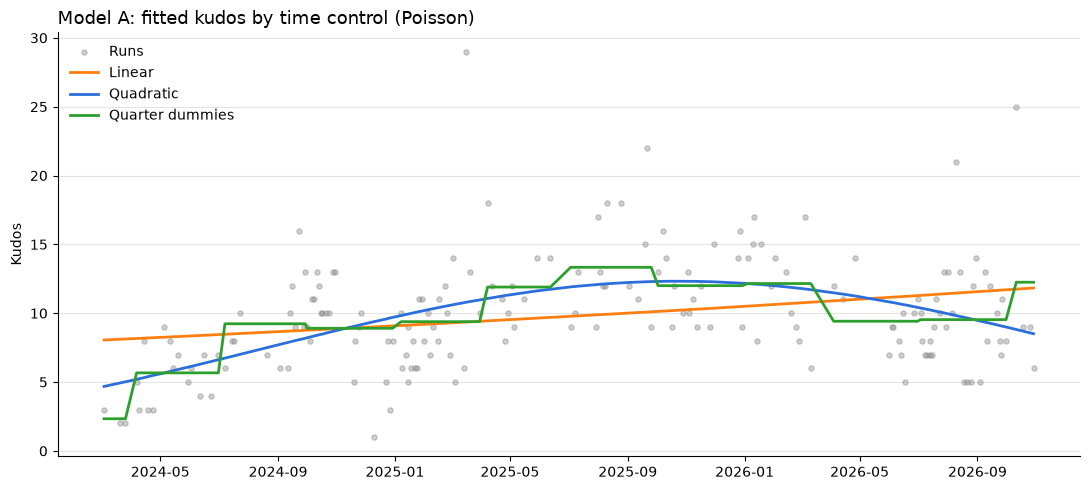

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(runs["activity_date"], runs["kudos_count"], s=14, alpha=0.4, color="#888888", label="Runs")

for name, color in [("Linear", "#ff7f0e"), ("Quadratic", "#2a6fdb"), ("Quarter dummies", "#2ca02c")]:
    ax.plot(runs["activity_date"], fits[("Poisson", name)].predict(runs),
            color=color, linewidth=2, label=name)

ax.set_title("Model A: fitted kudos by time control (Poisson)", loc="left", fontsize=13)
ax.set_ylabel("Kudos")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
runs["t_cu"] = runs["t"] ** 3

for family, fit_fn in [("Poisson", smf.poisson)]:
    quad  = fits[(family, "Quadratic")]
    cubic = fit_fn("kudos_count ~ t + t_sq + t_cu", data=runs).fit(disp=0)
    lr = 2 * (cubic.llf - quad.llf)
    print(f"{family}: cubic AIC = {cubic.aic:.2f} (quadratic {quad.aic:.2f}), "
          f"LR = {lr:.2f}, p = {stats.chi2.sf(lr, df=1):.4f}")

Poisson: cubic AIC = 945.02 (quadratic 944.27), LR = 1.25, p = 0.2628


### Interpretation: choice of time control --> Quadratic

| Family | Time control | Parameters | Log-likelihood | AIC |
|---|---|---|---|---|
| Poisson | Linear | 2 | −496.05 | 996.11 |
| Poisson | Quadratic | 3 | −469.14 | 944.27 |
| Poisson | Quarter dummies | 12 | −459.09 | 942.18 |

- **Quadratic vs linear:** adding the squared term strongly improves the fit (likelihood ratio test: LR = 53.8, p < 0.0001). A linear trend cannot capture the rise and later decline in kudos.
- **Quadratic vs quarter dummies:** the quarter dummies have a slightly lower AIC (942.2 vs 944.3), but they use 12 parameters instead of 3. We therefore use the **quadratic trend as the main time control** and keep quarter dummies as a robustness check for the final model.
- **Shape of the trend:** in the Poisson quadratic model, t = 0.193 and t² = −0.359 (both p < 0.001). Expected kudos rise from about 4.7 at the first run (March 2024) to a peak of about 12.3 around late October 2025, then decline to about 8.5 by October 2026. This matches the inverted U seen in the decomposition.
- **Limitation:** a quadratic is symmetric, so it may overstate the decline at the end of the period and slightly overpredict the earliest runs, as the quarter dummies suggest. Refitting the final model with quarter dummies will show whether this affects the conclusions.
- **Overdispersion:** the Pearson dispersion of the Poisson quadratic model is 1.32, which suggests kudos are overdispersed even after controlling for time. This is checked again in Part 3 once all predictors are included.
- **Cubic check:** adding a cubic term (t³) does not improve the fit (LR = 1.25, p = 0.26; AIC 945.0 vs 944.3 for the quadratic). This supports the quadratic as the main time control.

## Pre-modelling checks
Data checks before modelling: missing values, multicollinearity, how predictors change over time, and a manual re-check of the hand-entered data.

In [ ]:
predictors = ["distance_km", "elevation_gain", "pace_min_per_km", "achievements_count",
              "pr_best", "pr_2nd", "pr_3rd", "has_media", "has_custom_text",
              "is_weekend", "official_race", "t", "t_sq"]

missing = runs[["kudos_count"] + predictors].isna().sum()
print("Missing values in model variables:")
print(missing[missing > 0] if (missing > 0).any() else "none")

Missing values in model variables:
none


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xv = sm.add_constant(runs[predictors].astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=predictors, name="VIF")
display(vif.sort_values(ascending=False).round(2).to_frame())

,VIF
distance_km,2.44
t,1.82
pr_best,1.75
elevation_gain,1.74
pace_min_per_km,1.72
official_race,1.65
is_weekend,1.56
achievements_count,1.55
has_media,1.49
pr_2nd,1.42


In [ ]:
runs["year"] = runs["activity_date"].dt.year

by_year = runs.groupby("year").agg(
    n_runs=("kudos_count", "size"),
    mean_kudos=("kudos_count", "mean"),
    share_media=("has_media", "mean"),
    mean_distance_km=("distance_km", "mean"),
    share_long=("is_long", "mean"),
    share_custom_text=("has_custom_text", "mean"),
    share_pr=("pr_label", "mean"),
    share_weekend=("is_weekend", "mean"),
    n_races=("official_race", "sum"),
)
display(by_year.round(2))

# overlap between weekend and distance (noted in the report)
display(runs.groupby("is_weekend")["distance_km"].agg(["count", "mean", "median"]).round(2))

,n_runs,mean_kudos,share_media,mean_distance_km,share_long,share_custom_text,share_pr,share_weekend,n_races
year,,,,,,,,,
2024,52,7.67,0.48,7.89,0.29,0.81,0.50,0.42,1
2025,67,11.27,0.27,7.62,0.30,0.67,0.12,0.33,2
2026,59,10.27,0.37,7.25,0.22,0.64,0.19,0.31,3


,count,mean,median
is_weekend,,,
0,116,6.19,5.78
1,62,10.18,10.10


In [ ]:
# runs with 0 kudos: check they are real and not entry errors
print("Runs with 0 kudos:")
display(runs.loc[runs["kudos_count"] == 0,
                 ["activity_name", "activity_date", "distance_km", "kudos_count", "url"]])

# random sample of 10 runs to compare against Strava (kudos, media, PR badge)
check = runs.sample(10, random_state=67)[["activity_date", "activity_name", "kudos_count",
                                          "has_media", "pr_label_rank", "url"]]
display(check)

Runs with 0 kudos:


,activity_name,activity_date,distance_km,kudos_count,url


,activity_date,activity_name,kudos_count,has_media,pr_label_rank,url
163,2026-02-02 03:10:49,Afternoon Run,14,0,1.0,https://www.strava.com/activities/17256461379
207,2026-07-12 23:31:08,Evening Run,7,0,0.0,https://www.strava.com/activities/19289010388
145,2025-11-08 11:37:04,Pit stop to develop my pictures #amsterdamcore,11,0,0.0,https://www.strava.com/activities/16393206735
197,2026-06-12 18:21:32,Evening Run,7,0,0.0,https://www.strava.com/activities/18894264542
77,2025-01-28 18:24:22,Evening Run,11,0,0.0,https://www.strava.com/activities/13477163313
86,2025-02-27 16:52:51,Afternoon Run,7,0,0.0,https://www.strava.com/activities/13743193036
232,2026-09-20 21:42:07,Mtl t es belle pt2,10,1,3.0,https://www.strava.com/activities/20261287623
192,2026-04-26 04:11:41,Auckland run,14,1,0.0,https://www.strava.com/activities/18260209345
135,2025-10-02 16:05:41,Evening Run,13,0,0.0,https://www.strava.com/activities/16011479777
20,2024-06-30 17:03:35,New trail route unlocked,7,1,3.0,https://www.strava.com/activities/11777467131


### Pre-modelling checks: results

- **Missing values:** none of the model variables (kudos, the 10 predictors, official races and the time terms) have missing values, so all 178 runs are used in every model.
- **Multicollinearity:** all VIFs are below 2.5 (highest: distance 2.44, t 1.82, best-effort PR 1.75). Overlap between predictors is low, so the coefficients can be interpreted separately. This includes achievements and the PR dummies (VIF 1.55 and below 1.8), despite their correlation of 0.42.
- **Predictors change over time:** Photos, custom text and PRs were all most common in 2024, when the audience was smallest and kudos were lowest. Half of the 2024 runs had a PR, compared with 12% in 2025, which fits a new runner improving quickly at first. Without a time control, these features would be linked to low kudos simply because they were more frequent early on, and their effects would be underestimated. This confirms that the time control is needed to separate run characteristics from audience growth.
- **Weekend and distance overlap:** weekend runs are much longer than weekday runs (mean 10.2 km vs 6.2 km). Part of the raw weekend effect in the t-tests is therefore likely a distance effect, which the full model separates by including both.
- **Data accuracy:** no run has 0 kudos. A random sample of 10 runs (`random_state = 67`) was compared against Strava for kudos, media and PR badges.

## Conclusion of Part 1

**Decisions made:**
- Time control: quadratic in centred years (`t`, `t_sq`), chosen over linear (LR p < 0.0001), quarter dummies (similar AIC with 12 vs 3 parameters) and cubic (p = 0.26).
- Model family: Poisson, as proposed in the project pitch. Overdispersion is checked with the Pearson dispersion ratio (1.32 for the time-only model; see Part 3).
- PR coded as three dummies (`pr_best`, `pr_2nd`, `pr_3rd`; baseline = no PR). Never include `pr_label` together with the dummies.
- Official races: included as a control -> the refit without the 6 races is done as an 'extra' in Part 3.
- Heart rate and relative effort not used (missing for 105 of 178 runs).

**Model formulas (time + predictor groups):**
- A: `kudos_count ~ t + t_sq`
- B: A + `distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd` + `official_race`
- C: A + `has_media + has_custom_text`
- D: all of the above + `is_weekend`


# Part 2: Linear baseline (OLS)

**Goal:** Fit Model D from Part 1 using ordinary least squares (OLS) to create a simple and interpretable baseline. Will then check whether the main OLS assumptions are met and look at the limitations of using OLS to predict a count-based outcome such as kudos.

**Input:** `strava_activities.xlsx` (same file as Part 1). The data come from Part 1 in this notebook (178 public runs).

**Outputs:**
- `outputs/ols_coefficients.csv` : model coefficients, 95% confidence intervals and p-values, using both classical and robust (HC3) standard errors.
- `outputs/ols_influential_runs.csv` : runs identified as potentially influential based on leverage and Cook's distance.
- `outputs/ols_time_control_variants.csv` : comparison of key coefficients using three different time controls: linear, quadratic and quarter dummies.
- `figures/ols_*.png` : diagnostic plots used to assess model fit and check OLS assumptions.


In [ ]:
%pip install statsmodels openpyxl


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_white, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

os.makedirs("outputs", exist_ok=True)
os.makedirs("figures", exist_ok=True)
pd.set_option("display.width", 140)

## 2. OLS on the full model (Model D)
Formula from the Part 1 handover: time control + effort + presentation + weekend, with official races as a control.

In [ ]:
effort = "distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + official_race"
presentation = "has_media + has_custom_text"

formulas = {
    "A (time only)":          "kudos_count ~ t + t_sq",
    "B (time + effort)":      f"kudos_count ~ t + t_sq + {effort}",
    "C (time + presentation)": f"kudos_count ~ t + t_sq + {presentation}",
    "D (full)":               f"kudos_count ~ t + t_sq + {effort} + {presentation} + is_weekend",
}

ols = smf.ols(formulas["D (full)"], data=runs).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:            kudos_count   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.600
Method:                 Least Squares   F-statistic:                     21.38
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.78e-29
Time:                        16:05:36   Log-Likelihood:                -414.40
No. Observations:                 178   AIC:                             856.8
Df Residuals:                     164   BIC:                             901.3
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             10.5069      2

In [ ]:
# coefficient table: classical and robust (HC3) standard errors
ols_hc3 = smf.ols(formulas["D (full)"], data=runs).fit(cov_type="HC3")

ci, ci_r = ols.conf_int(), ols_hc3.conf_int()
coef_table = pd.DataFrame({
    "coef": ols.params,
    "ci_low": ci[0], "ci_high": ci[1], "p_value": ols.pvalues,
    "ci_low_HC3": ci_r[0], "ci_high_HC3": ci_r[1], "p_value_HC3": ols_hc3.pvalues,
})
display(coef_table.round(3))
print(f"R² = {ols.rsquared:.3f}   adjusted R² = {ols.rsquared_adj:.3f}   n = {int(ols.nobs)}")
coef_table.round(4).to_csv("outputs/ols_coefficients.csv")

,coef,ci_low,ci_high,p_value,ci_low_HC3,ci_high_HC3,p_value_HC3
Intercept,10.507,4.589,16.425,0.001,4.085,16.929,0.001
t,1.808,1.146,2.471,0.000,1.165,2.452,0.000
t_sq,-3.586,-4.414,-2.757,0.000,-4.505,-2.666,0.000
distance_km,0.431,0.262,0.600,0.000,0.222,0.641,0.000
elevation_gain,-0.002,-0.010,0.006,0.569,-0.010,0.006,0.581
pace_min_per_km,-0.443,-1.350,0.464,0.336,-1.425,0.539,0.376
achievements_count,-0.020,-0.074,0.034,0.460,-0.074,0.034,0.463
pr_best,1.569,-0.202,3.340,0.082,-0.686,3.823,0.173
pr_2nd,1.186,-1.017,3.389,0.289,-1.326,3.699,0.355
pr_3rd,-0.463,-1.872,0.947,0.518,-2.049,1.124,0.568


R² = 0.629   adjusted R² = 0.600   n = 178


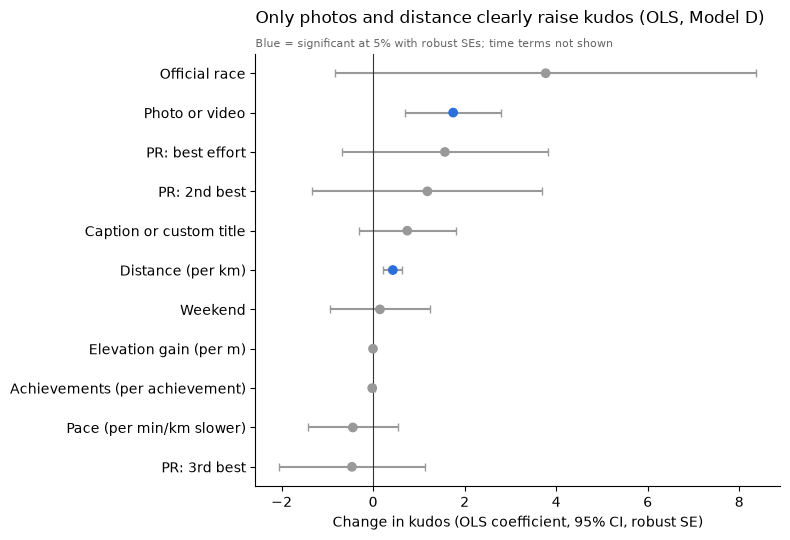

In [ ]:
# coefficient plot (95% CIs, robust HC3), time terms left out for readability
plot_tab = coef_table.drop(index=["Intercept", "t", "t_sq"])
order = plot_tab["coef"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(order))
sig = (plot_tab.loc[order, "p_value_HC3"] < 0.05)
ax.errorbar(plot_tab.loc[order, "coef"], y,
            xerr=[plot_tab.loc[order, "coef"] - plot_tab.loc[order, "ci_low_HC3"],
                  plot_tab.loc[order, "ci_high_HC3"] - plot_tab.loc[order, "coef"]],
            fmt="none", ecolor="#999999", elinewidth=1.5, capsize=3)
ax.scatter(plot_tab.loc[order, "coef"], y, color=np.where(sig, "#2a6fdb", "#999999"), zorder=3)
ax.axvline(0, color="#333333", linewidth=0.8)
nice = {"official_race": "Official race", "has_media": "Photo or video", "pr_best": "PR: best effort",
        "pr_2nd": "PR: 2nd best", "pr_3rd": "PR: 3rd best", "has_custom_text": "Caption or custom title",
        "distance_km": "Distance (per km)", "is_weekend": "Weekend", "elevation_gain": "Elevation gain (per m)",
        "achievements_count": "Achievements (per achievement)", "pace_min_per_km": "Pace (per min/km slower)"}
ax.set_yticks(y, [nice.get(v, v) for v in order])
ax.set_xlabel("Change in kudos (OLS coefficient, 95% CI, robust SE)")
ax.set_title("Only photos and distance clearly raise kudos (OLS, Model D)", loc="left", fontsize=12, pad=22)
ax.text(0, 1.015, "Blue = significant at 5% with robust SEs; time terms not shown", transform=ax.transAxes, fontsize=8, color="#666666")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.savefig("figures/ols_coefficients.png", dpi=200); plt.show()

### Interpretation: OLS coefficients

The full model explains around **60% of the variation in kudos** (adjusted R² = 0.600, n = 178). Each coefficient represents the expected change in kudos for a one-unit increase in a predictor, while keeping the other variables and time constant.

- **Distance (H3) - supported.** Each additional kilometre is associated with around 0.43 more kudos (95% CI: 0.22 to 0.64, robust p < 0.001). For example, a 10 km run would be expected to receive about 2 more kudos than a 5 km run.
- **Photo or video (H1) – supported.** Runs with photos or videos receive around 1.7 more kudos on average (95% CI: 0.7 to 2.8, robust p = 0.001).
- **Official race – large but uncertain.** The estimated effect is around +3.8 kudos. It is significant using classical standard errors (p = 0.007), but not with robust standard errors (p = 0.11). Since there are only 6 official races in the sample, this result should be treated as a control rather than a strong finding.
- **PR (H7) – not significant.** Best efforts are associated with around 1.6 additional kudos (robust p = 0.17). Second-best efforts add about 1.2, while third-best efforts are associated with a decrease of around 0.5. Although the direction is broadly consistent with H7, the groups are small (16, 8 and 21 runs), and all confidence intervals include zero.
- **Caption or custom title (H4) – not significant** The estimated effect is around +0.7 kudos (robust p = 0.17).
- **Weekend (H6) – no effect once distance is controlled** The coefficient is around +0.1 (p = 0.79). This suggests that the higher kudos seen for weekend runs in the initial t-tests were mainly explained by those runs being longer.
- **Pace (H5), elevation, achievements (H2) – no effect** All have p-values above 0.3.
- **Time:** Both time terms are strongly significant (t = +1.81 and t² = −3.59, p < 0.001). This supports the rise-and-fall pattern in audience engagement identified in Part 1.

The regression summary reports a high condition number, but this is likely driven by the different scales of the predictors, particularly elevation measured in metres alongside binary variables. Part 1's VIF results are all below 2.5, suggesting that multicollinearity is not a major concern.

## 3. Diagnostics
The OLS assumptions will be checked using four diagnostic plots. Residuals vs fitted values will assess linearity and constant variance, while the Q-Q plot will check normality. Leverage, studentized residuals and Cook's distance will help identify influential runs. Finally, residuals plotted in date order will help check independence.

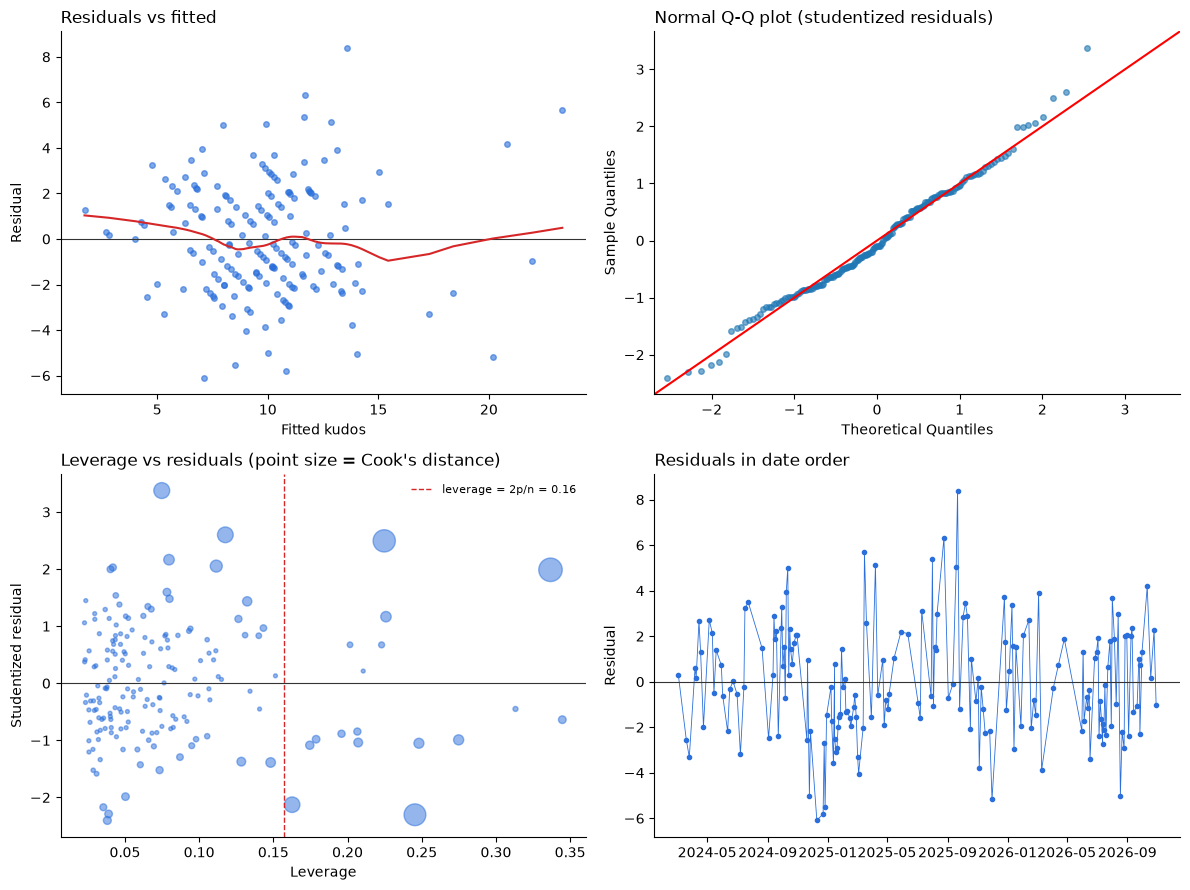

In [ ]:
infl = ols.get_influence()
fitted, resid = ols.fittedvalues, ols.resid
stud = infl.resid_studentized_internal
lev = infl.hat_matrix_diag
cooks = infl.cooks_distance[0]
n, p = int(ols.nobs), len(ols.params)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

ax = axes[0, 0]
ax.scatter(fitted, resid, s=16, alpha=0.6, color="#2a6fdb")
ax.axhline(0, color="#333333", linewidth=0.8)
low = sm.nonparametric.lowess(resid, fitted, frac=0.6)
ax.plot(low[:, 0], low[:, 1], color="#d62728", linewidth=1.5)
ax.set_xlabel("Fitted kudos"); ax.set_ylabel("Residual"); ax.set_title("Residuals vs fitted", loc="left")

sm.qqplot(stud, line="45", ax=axes[0, 1], markersize=4, alpha=0.6)
axes[0, 1].set_title("Normal Q-Q plot (studentized residuals)", loc="left")

ax = axes[1, 0]
ax.scatter(lev, stud, s=np.clip(cooks * 2000, 8, 300), alpha=0.5, color="#2a6fdb")
ax.axvline(2 * p / n, color="#d62728", linestyle="--", linewidth=1, label=f"leverage = 2p/n = {2*p/n:.2f}")
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_xlabel("Leverage"); ax.set_ylabel("Studentized residual")
ax.set_title("Leverage vs residuals (point size = Cook's distance)", loc="left"); ax.legend(frameon=False, fontsize=8)

ax = axes[1, 1]
ax.plot(runs["activity_date"], resid, marker="o", markersize=3, linewidth=0.6, color="#2a6fdb")
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_ylabel("Residual"); ax.set_title("Residuals in date order", loc="left")

for a in axes.flat:
    for side in ["top", "right"]:
        a.spines[side].set_visible(False)
plt.tight_layout(); plt.savefig("figures/ols_diagnostics.png", dpi=200); plt.show()

In [ ]:
# formal tests
# White's test by hand: statsmodels' het_white fails here because squared dummies equal the dummies
# (rank-deficient design), which gives wrong degrees of freedom. Keep only independent columns.
from itertools import combinations_with_replacement
from scipy import stats
X = ols.model.exog[:, 1:]                       # predictors without the constant
aux = [np.ones(len(X))] + [X[:, j] for j in range(X.shape[1])] +       [X[:, i] * X[:, j] for i, j in combinations_with_replacement(range(X.shape[1]), 2)]
A = np.column_stack(aux)
keep = []                                       # drop columns that add nothing (duplicates, all-zero products)
for j in range(A.shape[1]):
    if np.linalg.matrix_rank(A[:, keep + [j]]) > len(keep):
        keep.append(j)
A = A[:, keep]
r2 = sm.OLS(resid ** 2, A).fit().rsquared
white_lm, white_df = len(resid) * r2, A.shape[1] - 1
white_p = stats.chi2.sf(white_lm, white_df)
bp_lm, bp_p, _, _ = het_breuschpagan(resid, ols.model.exog)
jb, jb_p, skew, kurt = jarque_bera(resid)
dw = durbin_watson(resid)   # rows are in date order

tests = pd.DataFrame([
    [f"White (heteroskedasticity, df = {white_df})", white_lm, white_p],
    ["Breusch-Pagan (heteroskedasticity)", bp_lm, bp_p],
    ["Jarque-Bera (normality of residuals)", jb, jb_p],
    ["Durbin-Watson (autocorrelation, date order)", dw, np.nan],
], columns=["test", "statistic", "p_value"])
display(tests.round(3))
print(f"Residual skew = {skew:.2f}, kurtosis = {kurt:.2f}  (normal: 0 and 3)")
print("Durbin-Watson ≈ 2 means no first-order autocorrelation; below ~1.5 or above ~2.5 is a concern.")

,test,statistic,p_value
0,"White (heteroskedasticity, df = 83)",96.536,0.147
1,Breusch-Pagan (heteroskedasticity),32.518,0.002
2,Jarque-Bera (normality of residuals),1.942,0.379
3,"Durbin-Watson (autocorrelation, date order)",1.593,NaN


Residual skew = 0.25, kurtosis = 3.14  (normal: 0 and 3)
Durbin-Watson ≈ 2 means no first-order autocorrelation; below ~1.5 or above ~2.5 is a concern.


### Interpretation: diagnostics

- **Linearity:** the residuals-vs-fitted plot has no strong curve (the red smoother stays close to 0), so the linear form is acceptable.
- **Constant variance:** the residual spread grows with fitted kudos. The residual SD is about 2.2 in the lowest quarter of fitted values and 3.1 in the highest, and the variance of kudos rises from about 5.8 to 16.7. **Breusch-Pagan rejects constant variance (p = 0.002)**. White's test does not (p = 0.15), but it uses 83 auxiliary terms on 178 runs, so it has little power here. We therefore report **robust (HC3) standard errors** alongside the classical ones. This is the typical pattern for counts: the higher the average, the bigger the spread.
- **Normality:** the Q-Q plot follows the line closely and the Jarque-Bera test does not show any significant departure from normality (p = 0.38). The skewness (0.25) and kurtosis (3.14) are also close to what we would expect from a normal distribution.
- **Independence:** The Durbin-Watson statistic is 1.59 when residuals are ordered by date. Since it is slightly below 2, this suggests some mild positive autocorrelation, meaning that consecutive runs may have similar residual patterns. Part 3 checks this on the Poisson model: the residuals are autocorrelated, and adding the previous-five-run control removes it.

## 4. Influential runs
Flagged if Cook's distance > 4/n or leverage > 2p/n. Part 3 and the robustness checks reuse this list.

In [ ]:
runs["leverage"], runs["cooks_d"], runs["stud_resid"] = lev, cooks, stud
runs["fitted_ols"] = fitted

flag_cook = runs["cooks_d"] > 4 / n
flag_lev = runs["leverage"] > 2 * p / n
runs["flag_reason"] = np.select(
    [flag_cook & flag_lev, flag_cook, flag_lev],
    ["Cook's D and leverage", "Cook's D", "leverage"], default="")

cols = ["activity_id", "activity_date", "activity_name", "distance_km", "official_race",
        "kudos_count", "fitted_ols", "stud_resid", "leverage", "cooks_d", "flag_reason"]
influential = runs.loc[flag_cook | flag_lev, cols].sort_values("cooks_d", ascending=False)
print(f"Thresholds: Cook's D > {4/n:.3f}, leverage > {2*p/n:.3f}")
print("Flagged runs:", len(influential))
num = influential.select_dtypes("number").columns
influential[num] = influential[num].round(3)
display(influential)
influential.to_csv("outputs/ols_influential_runs.csv", index=False)

Thresholds: Cook's D > 0.022, leverage > 0.157
Flagged runs: 22


,activity_id,activity_date,activity_name,distance_km,official_race,kudos_count,fitted_ols,stud_resid,leverage,cooks_d,flag_reason
240,20544216799,2026-10-11 12:29:33,Semi de Montreal 2026,21.504,1,25,20.814,1.988,0.337,0.143,Cook's D and leverage
92,13896403815,2025-03-16 08:11:04,Semi de Lille,21.295,1,29,23.320,2.495,0.225,0.129,Cook's D and leverage
149,16607311967,2025-11-30 08:41:31,10k du 17eme,10.248,1,15,20.175,-2.304,0.245,0.123,Cook's D and leverage
133,15889402887,2025-09-21 09:53:40,Lunch Run,13.251,0,22,13.603,3.376,0.075,0.066,Cook's D
128,15573486255,2025-08-24 17:08:20,Evening Run,10.128,0,18,11.683,2.600,0.118,0.064,Cook's D
58,12973399949,2024-11-24 13:47:41,Sapharti10K boozy relay,10.098,0,9,14.034,-2.127,0.163,0.063,Cook's D and leverage
42,12630535596,2024-10-11 16:17:20,Evening Run,5.018,0,13,7.997,2.053,0.112,0.038,Cook's D
122,15306036906,2025-08-01 08:33:24,Morning Run,6.014,0,17,11.630,2.164,0.080,0.029,Cook's D
6,11177940534,2024-04-14 08:47:12,Beach & Bakery run run,4.502,0,8,5.347,1.166,0.226,0.028,Cook's D and leverage
17,11627854562,2024-06-11 14:49:05,Lunch Run,10.078,0,4,6.184,-0.992,0.275,0.027,Cook's D and leverage


### Interpretation: influential runs

A total of 22 runs are flagged as potentially influential. The most influential ones are the **official races**: including Semi de Montréal 2026 (25 kudos), Semi de Lille (29 kudos) and the 10k du 17ème (15 kudos, around 5 fewer than predicted). These runs have high leverage because there are only 6 races in the dataset, and most of them are long distances. As a result, a small number of runs can have a strong impact on the race and distance estimates.

Other flagged observations are regular runs that received more kudos than expected for their profile. For example, the 13 km Lunch Run received 22 kudos compared with 13.6 predicted. Some longer training runs are also flagged.

However, no single run appears to have an excessive influence on the model. The highest Cook's distance is 0.14, well below 1. The race coefficient was checked by refitting without the 6 official races (as an 'extra', at the end of Part 3): the distance rate ratio moved from 1.042 to 1.035, which both round to 1.04 (p = 0.003 without races), and the photo or video rate ratio from 1.178 to 1.183, which both round to 1.18 (p = 0.006) -> Neither conclusion really changes.

## 5. Why counts break OLS
Kudos are whole numbers that cannot be negative, and their spread tends to grow with their average. OLS assumes neither.

In [ ]:
print("Fitted values: min = %.2f, max = %.2f" % (fitted.min(), fitted.max()))
print("Negative fitted values:", int((fitted < 0).sum()))
print("Fitted values below 1 kudo:", int((fitted < 1).sum()))

# spread of residuals by level of fitted kudos (constant variance would give similar SDs)
bins = pd.qcut(fitted, 4, labels=["lowest 25%", "25-50%", "50-75%", "highest 25%"])
spread = pd.DataFrame({"fitted": fitted, "resid": resid, "kudos": runs["kudos_count"], "bin": bins}) \
    .groupby("bin", observed=True).agg(n=("resid", "size"), mean_fitted=("fitted", "mean"),
                                       mean_kudos=("kudos", "mean"), var_kudos=("kudos", "var"),
                                       sd_resid=("resid", "std"))
display(spread.round(2))

# what OLS predicts for a short, plain, early run (a realistic low-kudos profile)
example = runs.iloc[[0]].copy()
example[["distance_km", "elevation_gain", "achievements_count"]] = [3.0, 0.0, 0]
example[["pr_best", "pr_2nd", "pr_3rd", "official_race", "has_media", "has_custom_text", "is_weekend"]] = 0
example["pace_min_per_km"] = runs["pace_min_per_km"].max()
print("OLS prediction for a short, slow, plain run in March 2024: %.2f kudos" % ols.predict(example).iloc[0])

Fitted values: min = 1.71, max = 23.32
Negative fitted values: 0
Fitted values below 1 kudo: 0


,n,mean_fitted,mean_kudos,var_kudos,sd_resid
bin,,,,,
lowest 25%,45,6.18,6.40,5.84,2.18
25-50%,44,8.94,8.43,5.18,2.20
50-75%,44,10.57,10.45,5.42,2.38
highest 25%,45,13.86,14.24,16.69,3.07


OLS prediction for a short, slow, plain run in March 2024: -1.54 kudos


### Interpretation: why counts break OLS

- **Within the data, OLS behaves**: All predicted values are positive, with the lowest fitted value being 1.7 kudos. So, within the observed data, it does not produce any impossible predictions.
- **Outside the data, it predicts impossible values.** For example, for a short, slow and simple run in March 2024, OLS predicts -1.5 kudos. This is not possible because kudos are counts and cannot be negative. A count model with a log link avoids this issue because its predictions are always positive.
- **The spread grows with the mean** The variance increases from about 5.8 for lower fitted values to 16.7 for higher ones. OLS assumes that the variance stays constant, which is not the case here. This makes its usual standard errors less reliable. Poisson models are designed to handle this type of data.
- **Effects are additive.** OLS estimates that adding a photo brings around 1.7 extra kudos, whether a run would normally receive 3 or 15. A count model instead captures multiplicative effects (for example, a 15% increase), which makes more sense when the audience grows over time.

## 6. Time control variants
Same full model with three time controls. If the run-feature coefficients barely move, the conclusions do not depend on how follower growth is modelled.

In [ ]:
rest = f"{effort} + {presentation} + is_weekend"
time_variants = {
    "Linear": f"kudos_count ~ t + {rest}",
    "Quadratic (main)": f"kudos_count ~ t + t_sq + {rest}",
    "Quarter dummies": f"kudos_count ~ C(quarter_str) + {rest}",
}
key = ["distance_km", "elevation_gain", "pace_min_per_km", "achievements_count", "pr_best", "pr_2nd", "pr_3rd",
       "official_race", "has_media", "has_custom_text", "is_weekend"]

coef_cols, fit_rows = {}, []
for name, f in time_variants.items():
    m = smf.ols(f, data=runs).fit(cov_type="HC3")
    coef_cols[name] = m.params[key].round(3).astype(str) + np.where(m.pvalues[key] < 0.05, " *", "")
    fit_rows.append({"time control": name, "parameters": len(m.params),
                     "adj_R2": m.rsquared_adj, "AIC": m.aic})
variants = pd.DataFrame(coef_cols)
display(pd.DataFrame(fit_rows).round(3))
display(variants)
print("* = p < 0.05 (robust HC3)")
variants.to_csv("outputs/ols_time_control_variants.csv")

,time control,parameters,adj_R2,AIC
0,Linear,13,0.425,920.392
1,Quadratic (main),14,0.600,856.801
2,Quarter dummies,23,0.642,844.840


,Linear,Quadratic (main),Quarter dummies
distance_km,0.629 *,0.431 *,0.417 *
elevation_gain,-0.007,-0.002,-0.004
pace_min_per_km,-0.263,-0.443,-0.416
achievements_count,-0.037,-0.02,-0.007
pr_best,0.254,1.569,2.251
pr_2nd,-0.336,1.186,0.756
pr_3rd,-1.861 *,-0.463,-1.005
official_race,3.325,3.771,3.524
has_media,1.052,1.749 *,1.931 *
has_custom_text,1.235,0.746,0.759


* = p < 0.05 (robust HC3)


In [ ]:
# nested models A to D under OLS (for comparison with Part 3's count models)
nested = []
for name, f in formulas.items():
    m = smf.ols(f, data=runs).fit()
    nested.append({"model": name, "parameters": len(m.params), "R2": m.rsquared,
                   "adj_R2": m.rsquared_adj, "AIC": m.aic})
nested = pd.DataFrame(nested)
display(nested.round(3))

# F-tests: does each block add explanatory power over time alone?
mA, mB, mC, mD = [smf.ols(f, data=runs).fit() for f in formulas.values()]
for label, big in [("B vs A (effort)", mB), ("C vs A (presentation)", mC), ("D vs B (presentation + weekend, given effort)", mD)]:
    small = mB if label.startswith("D") else mA
    F, pv, df = big.compare_f_test(small)
    print(f"{label}: F = {F:.2f}, df = {int(df)}, p = {pv:.4f}")

,model,parameters,R2,adj_R2,AIC
0,A (time only),3,0.233,0.224,964.104
1,B (time + effort),11,0.575,0.550,874.921
2,C (time + presentation),5,0.378,0.364,930.621
3,D (full),14,0.629,0.600,856.801


B vs A (effort): F = 16.82, df = 8, p = 0.0000
C vs A (presentation): F = 20.27, df = 2, p = 0.0000
D vs B (presentation + weekend, given effort): F = 7.93, df = 3, p = 0.0001


### Interpretation: time controls and nested models

- **The quadratic fits far better than a linear trend:** Adjusted R² increases from 0.43 with a linear trend to 0.60 with a quadratic trend. Quarter dummies perform slightly better again (0.64), but require 9 additional parameters. This supports the choice made in Part 1.
- **The main conclusions hold across all three time control:** Distance is significant in every model, with an effect ranging from 0.42 to 0.63 additional kudos per km. Media is also significant with both the quadratic trend and quarter dummies (+1.7 to +1.9 kudos). However, with a simple linear trend, its effect drops to +1.1 and is no longer significant. This is likely because photos were more common in 2024, when the audience was still smaller. Without a good time control, the model struggles to capture the effect of photos.
- **Effort vs presentation (OLS view):** Effort alone increases adjusted R² from 0.22 (time only) to 0.55, while presentation alone increases it to 0.36. Both groups of variables significantly improve the model (F-tests p < 0.001). Presentation also adds explanatory power even after effort is included (D vs B, p < 0.001). Overall, effort explains more of the variation, but presentation, especially photos, also plays an important role. Part 3 will check whether these results hold using likelihood ratio tests and AIC on the count models.

## Conclusion of Part 2

OLS was fitted using Model D (quadratic time, effort, presentation, weekend and official races). The analysis included classical and robust (HC3) 95% confidence intervals, model diagnostics, influential runs, the three time-control alternatives and a comparison of Models A–D.

**Key results (OLS, robust SEs):**
- Adjusted R² = 0.60.
- Significant variables: distance (+0.43 kudos per km) and photo/video (+1.7 kudos), as well as both time terms.
- Not significant: PR dummies (best effort +1.6, p = 0.17), caption/custom title, weekend, pace, elevation and achievements. Official race has a positive effect (+3.8), but it is not statistically significant with robust SEs (p = 0.11), based on only 6 races.
- Effort explains more variation than presentation, but both contribute significantly to the model.

**Diagnostics to carry forward:**
- The variance increases with the mean (Breusch-Pagan p = 0.002), supporting the move to count models.
- Residuals are close to normally distributed, with no strong evidence of non-linearity.
- Durbin-Watson = 1.59, suggesting possible mild autocorrelation. Part 3 checks this on the Poisson model: the residuals are autocorrelated, and adding the previous-five-run control removes it.

**Files:**
- `outputs/ols_coefficients.csv` – coefficient table (classical and HC3)
- `outputs/ols_influential_runs.csv` – 22 flagged runs (Cook's D > 4/n or leverage > 2p/n), for the robustness refits
- `outputs/ols_time_control_variants.csv` – coefficients under linear, quadratic and quarter-dummy time controls
- `figures/ols_coefficients.png`, `figures/ols_diagnostics.png` – for the slides


# Part 3: Count models (Poisson)

Kudos are whole numbers (0, 1, 2, ...), so a count model is a better fit than the OLS baseline in Part 2. This part fits Poisson regression (a generalized linear model with a log link, using the same sm.GLM function as Lecture 4, with a Poisson family), compares the four nested models A to D, checks for overdispersion, and reports the effects as rate ratios.

**Scope:** Poisson regression, as proposed in the project pitch, with likelihood-ratio tests, AIC/BIC, robust standard errors, and residual checks (Ljung-Box, Durbin-Watson). The overdispersion check is the Pearson dispersion ratio.

**Input:** `strava_activities.xlsx` (same as Parts 1 and 2).

**Outputs:**
- `outputs/poisson_nested_fit.csv`: AIC, BIC and log-likelihood for models A to D.
- `outputs/poisson_rate_ratios.csv`: rate ratios with classical and robust (HC1) standard errors for model D.
- `outputs/poisson_robustness.csv`: quarter-dummy and previous-five-run sensitivity checks.


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

## 1. Nested Poisson models A to D

- **A:** time only (`t`, `t_sq`)
- **B:** A + effort (distance, elevation, pace, achievements, PR dummies, official race)
- **C:** A + presentation (media, custom text)
- **D:** all of the above + weekend. D is the main model, and it was fixed as the main model before fitting, following the Part 2 handover.

In [ ]:
effort = "distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + official_race"
presentation = "has_media + has_custom_text"

formulas = {
    "A (time only)":           "kudos_count ~ t + t_sq",
    "B (time + effort)":       f"kudos_count ~ t + t_sq + {effort}",
    "C (time + presentation)": f"kudos_count ~ t + t_sq + {presentation}",
    "D (full)":                f"kudos_count ~ t + t_sq + {effort} + {presentation} + is_weekend",
}

fits = {name: smf.glm(f, data=runs, family=sm.families.Poisson()).fit() for name, f in formulas.items()}

nested = pd.DataFrame([{"model": name, "parameters": len(m.params), "log_lik": m.llf,
                        "AIC": m.aic, "BIC": m.bic_llf} for name, m in fits.items()]).set_index("model")
display(nested.round(2))
nested.round(3).to_csv("outputs/poisson_nested_fit.csv")

,parameters,log_lik,AIC,BIC
model,,,,
A (time only),3,-469.14,944.27,953.82
B (time + effort),11,-425.72,873.45,908.44
C (time + presentation),5,-448.34,906.69,922.60
D (full),14,-418.04,864.08,908.63


### Interpretation: nested fit

- Within the Poisson family, AIC is lowest for D (864.08), about 9.4 points below B (873.45). A (944.27) and C (906.69) are clearly worse.
- BIC is essentially tied between B (908.44) and D (908.63): BIC charges about 5.2 points per parameter (ln 178), against 2 for AIC. D's three extra parameters are worth keeping under AIC but not clearly under BIC.
- Model A is the weakest on both criteria, so time alone leaves much of the variation unexplained.


## 2. Overdispersion check (Pearson dispersion)

A Poisson model assumes the variance equals the mean. The Pearson dispersion ratio (Pearson chi-squared divided by residual degrees of freedom) is about 1 if that holds, and clearly above 1 if the counts are overdispersed. Part 1 flagged overdispersion in the time-only model, so the check is run for every model.

In [ ]:
disp = pd.DataFrame({
    "model": list(fits),
    "Pearson chi2": [m.pearson_chi2 for m in fits.values()],
    "df residual": [m.df_resid for m in fits.values()],
}).set_index("model")
disp["Pearson chi2 / df"] = disp["Pearson chi2"] / disp["df residual"]
display(disp.round(3))

,Pearson chi2,df residual,Pearson chi2 / df
model,,,
A (time only),230.233,175,1.316
B (time + effort),125.008,167,0.749
C (time + presentation),181.503,173,1.049
D (full),110.001,164,0.671


### Interpretation: overdispersion

- Model A has a dispersion ratio of 1.32, so the time-only counts vary more than Poisson predicts. This is the overdispersion that Part 1 flagged.
- Adding the effort and presentation variables removes it: B is 0.75, C is 1.05 and the main model D is 0.67 (D shows no overdispersion). It is slightly below 1, which means the Poisson standard errors may be somewhat conservative.
- Robust standard errors are still reported in section 4. They don't depend on the Poisson variance assumption, so they serve as a check on the classical standard errors.

Part 1’s time-only Poisson model reproduces the Part 3 model A results: a log-likelihood of −469.14 and a Pearson dispersion of 1.32.

## 3. Likelihood-ratio tests between nested models

Each test compares a smaller model with a bigger one that includes everything in the smaller one. If the bigger model fits much better, the test gives a small p-value. The test statistic is 2 × (the bigger model's log-likelihood − the smaller model's), and we compare it to a chi-squared distribution with degrees of freedom equal to the number of extra parameters.


In [ ]:
def lr_test(small, big):
    lr = 2 * (big.llf - small.llf)
    df = len(big.params) - len(small.params)
    return lr, df, stats.chi2.sf(lr, df)

rows = []
for small, big in [("A (time only)", "B (time + effort)"),
                   ("A (time only)", "C (time + presentation)"),
                   ("B (time + effort)", "D (full)"),
                   ("C (time + presentation)", "D (full)")]:
    lr, df, p = lr_test(fits[small], fits[big])
    rows.append({"comparison": f"{small} -> {big}", "LR": lr, "df": df, "p_value": p})
lr_table = pd.DataFrame(rows).set_index("comparison")
display(lr_table.round(4))

,LR,df,p_value
comparison,,,
A (time only) -> B (time + effort),86.8273,8,0.0000
A (time only) -> C (time + presentation),41.5857,2,0.0000
B (time + effort) -> D (full),15.3607,3,0.0015
C (time + presentation) -> D (full),60.6023,9,0.0000


### Interpretation: LR tests

- **Effort helps:** B improves on A by a large margin (LR = 86.8, 8 df, p < 0.0001).
- **Presentation helps:** C improves on A (LR = 41.6, 2 df, p < 0.0001).
- **Presentation still adds after effort:** D improves on B (LR = 15.4, 3 df, p = 0.0015). Media, custom text and weekend add explanatory power beyond distance, PRs and the other effort variables.
- **Effort vs presentation:** the two blocks contribute to fit, and the effort block is the larger of the two. This matches the OLS answer in Part 2.

These LR tests use the classical Poisson variance. Since the dispersion ratio for D is below 1, they are not inflated by overdispersion.

## 4. Rate ratios for the main model (D)

Poisson coefficients are on the log scale, so `exp(coef)` is a **rate ratio**: the multiplicative change in expected kudos for a one-unit increase in the predictor, holding the others constant. E.g., a rate ratio of 1.18 means about 18% more kudos. Both classical and robust (HC1) standard errors are shown.

In [ ]:
main = fits["D (full)"]
robust = smf.glm(formulas["D (full)"], data=runs, family=sm.families.Poisson()).fit(cov_type="HC1")

ci = main.conf_int()
rr = pd.DataFrame({
    "coef": main.params,
    "rate_ratio": np.exp(main.params),
    "RR_low": np.exp(ci[0]),
    "RR_high": np.exp(ci[1]),
    "p_classic": main.pvalues,
    "p_robust_HC1": robust.pvalues,
})
display(rr.round(4))
rr.round(4).to_csv("outputs/poisson_rate_ratios.csv")

,coef,rate_ratio,RR_low,RR_high,p_classic,p_robust_HC1
Intercept,2.4907,12.0691,5.9124,24.6369,0.0000,0.0000
t,0.2038,1.2261,1.1252,1.3360,0.0000,0.0000
t_sq,-0.4057,0.6665,0.5992,0.7413,0.0000,0.0000
distance_km,0.0408,1.0417,1.0215,1.0622,0.0000,0.0000
elevation_gain,-0.0001,0.9999,0.9990,1.0007,0.7464,0.6048
pace_min_per_km,-0.0639,0.9381,0.8412,1.0462,0.2507,0.1160
achievements_count,-0.0017,0.9983,0.9919,1.0047,0.5932,0.4200
pr_best,0.0793,1.0826,0.8723,1.3436,0.4716,0.4541
pr_2nd,0.0683,1.0707,0.8358,1.3716,0.5886,0.3997
pr_3rd,-0.0544,0.9471,0.7921,1.1325,0.5511,0.4802


### Interpretation: rate ratios (model D)

- **Distance (H3) - supported:** Each extra km multiplies expected kudos by about 1.04, or about 4% (p < 0.001 with both standard errors). Ten extra km multiplies expected kudos by about 1.5, holding everything else constant.
- **Photo or video (H1) - supported:** Runs with a photo or video get about 18% more kudos (rate ratio 1.18, 95% CI roughly 1.05 to 1.32). The robust p-value is 0.0008.
- **Caption or custom text (H4) - not significant:** Rate ratio 1.08 (p = 0.20 classical, 0.15 robust).
- **PR (H7) - not significant:** Best effort 1.08, 2nd best 1.07, 3rd best 0.95. All intervals include 1, and the groups are small (16, 8 and 21 runs).
- **Official race - not significant:** Rate ratio 1.16 (p = 0.31 classical, 0.21 robust). Only 6 races are in the sample, so this is treated as a control.
- **Weekend (H6) - no effect after distance:** Rate ratio 1.02 (p = 0.72).
- **Pace (H5), elevation and achievements (H2) - no effect:** All p-values above 0.2.
- **Time:** the quadratic trend is strongly significant (t p < 0.001, t_sq p < 0.001).

**Compared with OLS (Part 2):** the same variables are significant (distance and media), and the signs agree. The OLS effect of distance (+0.43 kudos per km) and the Poisson effect (about 4% per km, which is about 0.4 kudos at the mean of 9.8) describe the same relationship, but the Poisson version cannot predict negative kudos.

## 5. Robustness checks

Two robustness checks are run on model D:
1. **Quarter dummies instead of the quadratic trend:** Each quarter of the year gets its own indicator, replacing the smooth time curve (we used this in Part 1 as the robustness check for the time control)

2. **Average of the previous five runs:** We added the average kudos from the five runs before each run. The residual check in Section 6 showed the residuals were correlated from one run to the next, so we tested this control. Because it uses the outcome itself as a predictor, it’s a sensitivity check and not part of the main model. The first five runs have no five earlier runs, so the sample is 173.

In [ ]:
base = formulas["D (full)"]
quarter = smf.glm(f"kudos_count ~ C(quarter_str) + {effort} + {presentation} + is_weekend",
                  data=runs, family=sm.families.Poisson()).fit()

runs["prev5_kudos"] = runs["kudos_count"].shift(1).rolling(5).mean()
sens = runs.dropna(subset=["prev5_kudos"]).copy()
main_same = smf.glm(base, data=sens, family=sm.families.Poisson()).fit()
with_prev5 = smf.glm(base + " + prev5_kudos", data=sens, family=sm.families.Poisson()).fit()

keep = ["distance_km", "has_media", "has_custom_text", "official_race", "pr_best", "pr_2nd", "pr_3rd",
        "is_weekend", "elevation_gain", "pace_min_per_km", "achievements_count"]
robust_tab = pd.DataFrame({
    "RR_main_D": np.exp(main.params[keep]),
    "p_main_D": main.pvalues[keep],
    "RR_quarter_dummies": np.exp(quarter.params[keep]),
    "p_quarter_dummies": quarter.pvalues[keep],
    "RR_main_D_sample_173": np.exp(main_same.params[keep]),
    "RR_with_prev5": np.exp(with_prev5.params[keep]),
    "p_with_prev5": with_prev5.pvalues[keep],
})
display(robust_tab.round(3))
print(f"AIC: quarter dummies = {quarter.aic:.2f} (23 params), main D = {main.aic:.2f} (14 params)")
print(f"prev5_kudos coefficient = {with_prev5.params['prev5_kudos']:.4f}, "
      f"rate ratio = {np.exp(with_prev5.params['prev5_kudos']):.3f}, p = {with_prev5.pvalues['prev5_kudos']:.4f}")
robust_tab.round(4).to_csv("outputs/poisson_robustness.csv")

,RR_main_D,p_main_D,RR_quarter_dummies,p_quarter_dummies,RR_main_D_sample_173,RR_with_prev5,p_with_prev5
distance_km,1.042,0.000,1.038,0.000,1.039,1.040,0.000
has_media,1.178,0.006,1.207,0.002,1.202,1.199,0.003
has_custom_text,1.083,0.197,1.082,0.221,1.065,1.064,0.320
official_race,1.157,0.307,1.114,0.464,1.123,1.166,0.283
pr_best,1.083,0.472,1.201,0.122,1.166,1.131,0.277
pr_2nd,1.071,0.589,1.044,0.754,1.097,1.072,0.581
pr_3rd,0.947,0.551,0.894,0.235,0.948,0.921,0.371
is_weekend,1.022,0.721,1.022,0.741,1.009,1.011,0.865
elevation_gain,1.000,0.746,1.000,0.627,1.000,1.000,0.593
pace_min_per_km,0.938,0.251,0.949,0.370,0.950,0.950,0.357


AIC: quarter dummies = 861.78 (23 params), main D = 864.08 (14 params)
prev5_kudos coefficient = 0.0397, rate ratio = 1.040, p = 0.0020


### Interpretation: robustness

- **Quarter dummies agree with the quadratic:** Distance, photo or video  and the other effects are close to the main model. AIC is slightly lower with quarter dummies , so the quadratic trend remains the main control.

- **The conclusions do not change with the previous-five-run control:** Distance stays at about 1.04 per km and photo or video at about 1.20. The previous-five-run coefficient is positive. It is a sensitivity check, and it does not change the main findings.

- **The main effects hold across all three versions:** Distance and photo or video are the two consistent effects.

## 6. Residual checks on model D

Residuals are checked in date order, as in Part 2. Two tests are used: the Ljung-Box test (no autocorrelation up to lag 10) and the Durbin-Watson statistic (about 2 means no first-order autocorrelation). The checks are run on the main model and on the model with the previous-five-run control.

In [ ]:
def residual_checks(model, label):
    r = model.resid_pearson
    lb = acorr_ljungbox(r, lags=[10], return_df=True)
    acf = [np.corrcoef(r[:-k], r[k:])[0, 1] for k in range(1, 11)]
    return {"model": label, "ACF lag 1": acf[0], "ACF lag 2": acf[1], "ACF lag 3": acf[2], "ACF lag 4": acf[3],
            "Ljung-Box (lag 10) p": lb["lb_pvalue"].iloc[0], "Durbin-Watson": durbin_watson(r)}

checks = pd.DataFrame([residual_checks(main, "D (main)"),
                       residual_checks(with_prev5, "D + prev5_kudos (sample 173)")]).set_index("model")
display(checks.round(3))

,ACF lag 1,ACF lag 2,ACF lag 3,ACF lag 4,Ljung-Box (lag 10) p,Durbin-Watson
model,,,,,,
D (main),0.246,0.230,0.203,0.234,0.000,1.506
D + prev5_kudos (sample 173),0.090,0.075,0.078,0.118,0.389,1.803


### Interpretation: residuals

- **In the main model D, autocorrelation is present:** The residual ACF is about 0.2 to 0.25 at lags 1 to 4, the Ljung-Box test is significant, and Durbin-Watson is 1.51. This matches the mild autocorrelation flagged in Part 2 where the Durbin-Watson was 1.59 for OLS.

- **Adding the previous-five-run control removes it:** The Ljung-Box p-value is about 0.39 and Durbin-Watson is about 1.80.

- **Interpretation:** Runs close together in time have related kudos, which the time trend does not fully capture. The main effects are unchanged after the control, so the autocorrelation does not change the conclusions. The Poisson standard errors in D should still be read with the robust results in section 4.

# Part 4: Checks and robustness

In this part we check the candidate final model which is model D from Part 3 and then lock the final model.

Steps:
1. Check if the residuals are autocorrelated (ACF, Ljung-Box, Durbin-Watson), with runs in date order.
2. If they are, add the average kudos of the previous 5 runs (`prev5_kudos`) and refit.
3. Refit with quarter dummies, without the 6 official races, and without the influential runs from Part 2. Optional: log of elevation and achievements, and a media × time interaction.
4. VIF check.
5. Lock the final model.

All models in this part use robust standard errors, like in Part 3.


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

# the time-series checks need the runs in date order
print("Runs in date order:", runs["activity_date"].is_monotonic_increasing)
assert runs["activity_date"].is_monotonic_increasing, "Sort runs by activity_date before Part 3."

def fit_poisson(formula, data):
    # drops a predictor that is constant in the sample (e.g. official_race once the races are removed)
    lhs, rhs = formula.split("~")
    terms = [x.strip() for x in rhs.split("+")]
    keep = [x for x in terms if not (x in data.columns and data[x].nunique() <= 1)]
    for x in set(terms) - set(keep):
        print(f"  note: '{x}' is constant in this sample and is dropped from the model")
    return smf.glm(lhs + "~ " + " + ".join(keep), data=data, family=sm.families.Poisson()).fit(cov_type="HC1")

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

Runs in date order: True


## 1. Time-series check on model D

We look at the Pearson residuals of model D in date order:
- **ACF** for lags 1 to 15. Bars outside the ±1.96/√n band mean the residuals are correlated.
- **Ljung-Box** at lags 5 and 10. p < 0.05 means the residuals are autocorrelated.
- **Durbin-Watson**: close to 2 means no autocorrelation, below 1.5 is a problem.

Runs are not evenly spaced, so lag 1 means the previous run, not the previous day.

In [ ]:
cand = fit_poisson(formulas["D (full)"], runs)

def ts_checks(model, label, max_lag=15):
    r = np.asarray(model.resid_pearson)
    n_r = len(r)
    acf_vals = np.array([np.corrcoef(r[:-k], r[k:])[0, 1] for k in range(1, max_lag + 1)])
    lb = acorr_ljungbox(r, lags=[5, 10], return_df=True)
    row = {"model": label, "n": n_r,
           "ACF lag 1": acf_vals[0], "ACF lag 2": acf_vals[1], "ACF lag 3": acf_vals[2],
           f"lags outside band (of {max_lag})": int((np.abs(acf_vals) > 1.96 / np.sqrt(n_r)).sum()),
           "Ljung-Box lag 5 p": lb["lb_pvalue"].iloc[0],
           "Ljung-Box lag 10 p": lb["lb_pvalue"].iloc[1],
           "Durbin-Watson": durbin_watson(r)}
    return row, acf_vals

row_D, acf_D = ts_checks(cand, f"D (candidate, n = {len(runs)})")
display(pd.DataFrame([row_D]).set_index("model").round(3))

needs_prev5 = row_D["Ljung-Box lag 10 p"] < 0.05
print("Residuals autocorrelated (Ljung-Box lag 10 p < 0.05):", needs_prev5)

,n,ACF lag 1,ACF lag 2,ACF lag 3,lags outside band (of 15),Ljung-Box lag 5 p,Ljung-Box lag 10 p,Durbin-Watson
model,,,,,,,,
"D (candidate, n = 178)",178,0.246,0.23,0.203,4,0.0,0.0,1.506


Residuals autocorrelated (Ljung-Box lag 10 p < 0.05): True


## 2. Adding the previous-5-runs average

`prev5_kudos` is the average kudos of the 5 runs before each run. It shows how active the audience was just before the post. The first 5 runs don't have 5 earlier runs, so the sample goes from 178 to 173 runs.

We also refit model D on the same 173 runs, so the two models can be compared with a likelihood ratio test.

In [ ]:
sens = runs.dropna(subset=["prev5_kudos"]).copy()
cand_173 = fit_poisson(formulas["D (full)"], sens)
cand_prev5 = fit_poisson(formulas["D (full)"] + " + prev5_kudos", sens)

lr, df_lr, p_lr = lr_test(cand_173, cand_prev5)
print(f"LR test, D vs D + prev5_kudos (n = {len(sens)}): LR = {lr:.2f}, df = {df_lr}, p = {p_lr:.4f}")
print(f"prev5_kudos rate ratio = {np.exp(cand_prev5.params['prev5_kudos']):.3f} per extra kudo "
      f"in the 5-run average (robust p = {cand_prev5.pvalues['prev5_kudos']:.4f})")

row_173, acf_173 = ts_checks(cand_173, f"D (same sample, n = {len(sens)})")
row_prev5, acf_prev5 = ts_checks(cand_prev5, f"D + prev5_kudos (n = {len(sens)})")
ts_table = pd.DataFrame([row_D, row_173, row_prev5]).set_index("model")
display(ts_table.round(3))
ts_table.round(4).to_csv("outputs/ts_checks.csv")

LR test, D vs D + prev5_kudos (n = 173): LR = 9.50, df = 1, p = 0.0021
prev5_kudos rate ratio = 1.040 per extra kudo in the 5-run average (robust p = 0.0000)


,n,ACF lag 1,ACF lag 2,ACF lag 3,lags outside band (of 15),Ljung-Box lag 5 p,Ljung-Box lag 10 p,Durbin-Watson
model,,,,,,,,
"D (candidate, n = 178)",178,0.246,0.230,0.203,4,0.000,0.000,1.506
"D (same sample, n = 173)",173,0.231,0.227,0.205,4,0.000,0.000,1.530
D + prev5_kudos (n = 173),173,0.090,0.075,0.078,0,0.328,0.389,1.803


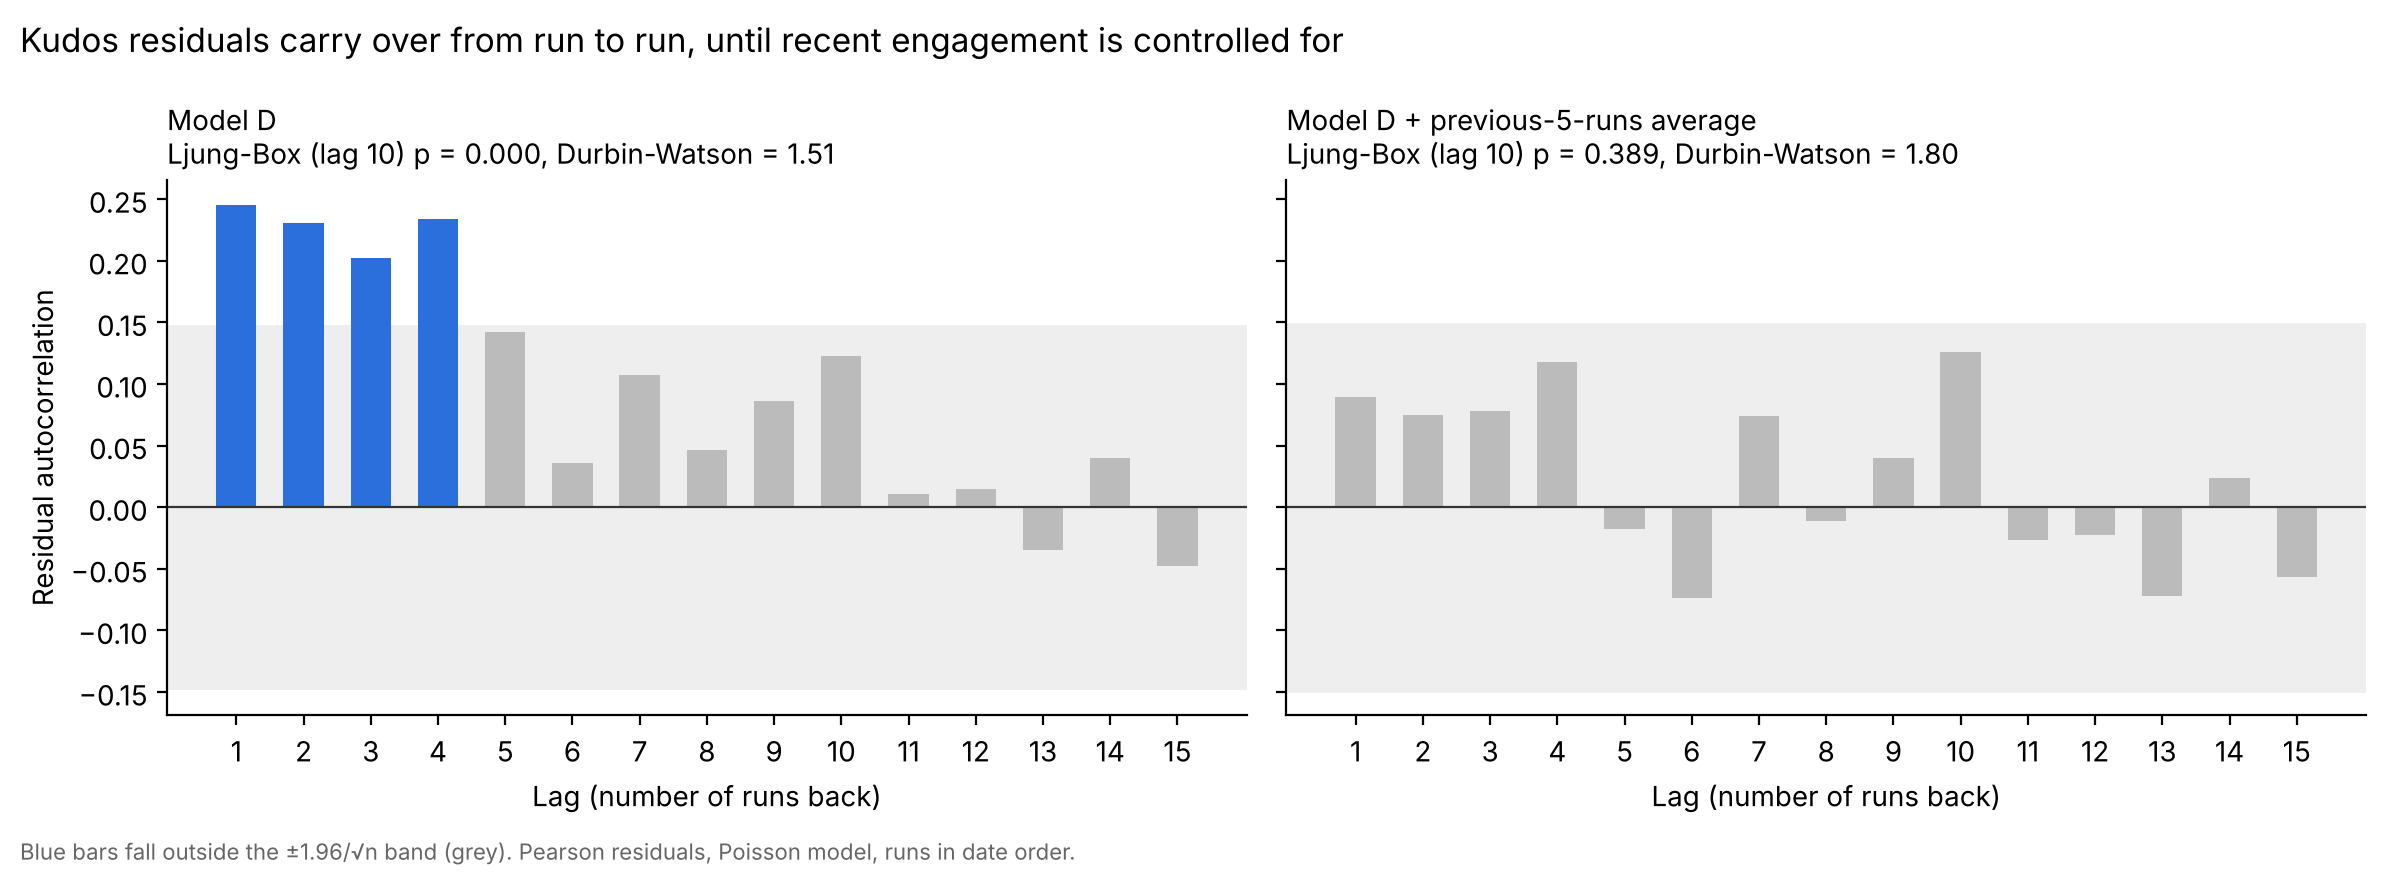

In [ ]:
lags = np.arange(1, len(acf_D) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, vals, n_r, title, row in [
        (axes[0], acf_D, row_D["n"], "Model D", row_D),
        (axes[1], acf_prev5, row_prev5["n"], "Model D + previous-5-runs average", row_prev5)]:
    band = 1.96 / np.sqrt(n_r)
    outside = np.abs(vals) > band
    ax.bar(lags, vals, width=0.6, color=np.where(outside, "#2a6fdb", "#bbbbbb"))
    ax.axhspan(-band, band, color="#eeeeee", zorder=0)
    ax.axhline(0, color="#333333", linewidth=0.8)
    ax.set_xticks(lags)
    ax.set_xlabel("Lag (number of runs back)")
    ax.set_title(f"{title}\nLjung-Box (lag 10) p = {row['Ljung-Box lag 10 p']:.3f}, "
                 f"Durbin-Watson = {row['Durbin-Watson']:.2f}", loc="left", fontsize=10)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Residual autocorrelation")
fig.suptitle("Kudos residuals carry over from run to run, until recent engagement is controlled for",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, -0.02, "Blue bars fall outside the ±1.96/√n band (grey). Pearson residuals, Poisson model, runs in date order.",
         fontsize=8, color="#666666")
plt.tight_layout(); plt.savefig("figures/ts_check_acf.png", dpi=200, bbox_inches="tight"); plt.show()

### Interpretation: time-series check

- **Model D's residuals are autocorrelated.** The lag-1 ACF is 0.25 and lags 2 to 4 are around 0.2. 4 of the 15 lags are outside the band. Ljung-Box p < 0.001 at lags 5 and 10, and Durbin-Watson is 1.51. So when a run gets more kudos than expected, the next runs often do too. The time trend captures the long-term change in the audience, but not shorter ups and downs.

- **It is not because of the smaller sample.** Model D on the same 173 runs gives about the same results..

- **Adding `prev5_kudos` fixes it.** The lag-1 ACF drops to 0.09, no lag is outside the band, Ljung Box p = 0.39 and Durbin-Watson = 1.80. `prev5_kudos` is also significant, each extra kudo in the 5 run average gives about 4% more kudos.

- **Decision:** we add `prev5_kudos` to the final model, as planned. Without it the residuals are not independent and the standard errors are too small. It is a control variable and not a finding since Eglantine can't change it.

## 3. Robustness refits

Each refit changes one thing in the final model:

| Refit | What changes |
|---|---|
| Quarter dummies | quarter dummies instead of `t` and `t_sq` |
| Without official races | the 6 races are removed |
| Without influential runs | the runs flagged in Part 2 are removed (21 of the 22 are in the 173-run sample) |
| Log of elevation and achievements (optional) | log(1 + x) instead of x, since both are very skewed |
| Media × time (optional) | adds `has_media:t`, to see if the photo effect changes over time |

AIC can only be compared between models fitted on the same runs.

In [ ]:
FINAL_FORMULA = formulas["D (full)"] + (" + prev5_kudos" if needs_prev5 else "")
final_data = sens if needs_prev5 else runs
print("Final model formula:\n ", FINAL_FORMULA)
print("n =", len(final_data))

log_formula = (FINAL_FORMULA.replace("elevation_gain", "np.log1p(elevation_gain)")
                            .replace("achievements_count", "np.log1p(achievements_count)"))
specs = {
    "Final model":              (FINAL_FORMULA, final_data),
    "Quarter dummies":          (FINAL_FORMULA.replace("t + t_sq", "C(quarter_str)"), final_data),
    "Without official races":   (FINAL_FORMULA.replace(" + official_race", ""),
                                 final_data[final_data["official_race"] == 0]),
    "Without influential runs": (FINAL_FORMULA, final_data[final_data["flag_reason"] == ""]),
    "Log elevation & achiev.":  (log_formula, final_data),
    "Media × time":             (FINAL_FORMULA + " + has_media:t", final_data),
}
rob_models = {name: fit_poisson(f, d) for name, (f, d) in specs.items()}

key = ["distance_km", "has_media", "has_custom_text", "is_weekend", "pace_min_per_km",
       "elevation_gain", "achievements_count", "pr_best", "pr_2nd", "pr_3rd", "official_race",
       "prev5_kudos", "has_media:t"]

def lookup(model, var):
    # also finds the log(1 + x) version of the variable
    for name in [var, f"np.log1p({var})"]:
        if name in model.params.index:
            return name, model.params[name], model.pvalues[name]
    return None

cells, long_rows = {}, []
for spec, m in rob_models.items():
    col = {}
    ci = m.conf_int()
    for var in key:
        hit = lookup(m, var)
        if hit is None:
            col[var] = "—"
            continue
        name, b, p = hit
        col[var] = f"{np.exp(b):.3f}{stars(p)}" + (" (log)" if name.startswith("np.log1p") else "")
        long_rows.append({"spec": spec, "var": var, "RR": np.exp(b),
                          "low": np.exp(ci.loc[name, 0]), "high": np.exp(ci.loc[name, 1]), "p": p})
    r_ = np.asarray(m.resid_pearson)
    col["n"] = f"{int(m.nobs)}"
    col["AIC"] = f"{m.aic:.1f}"
    col["Pearson dispersion"] = f"{m.pearson_chi2 / m.df_resid:.2f}"
    col["Ljung-Box lag 10 p"] = f"{acorr_ljungbox(r_, lags=[10], return_df=True)['lb_pvalue'].iloc[0]:.3f}"
    cells[spec] = col

rob_table = pd.DataFrame(cells)
rob_long = pd.DataFrame(long_rows)
if not needs_prev5:
    rob_table = rob_table.drop(index="prev5_kudos")
display(rob_table)
print("Rate ratios; * p < 0.05, ** p < 0.01, *** p < 0.001 (robust HC1). '(log)' = rate ratio per 1-unit change in log(1 + x).")
rob_table.to_csv("outputs/robustness_table.csv")

Final model formula:
  kudos_count ~ t + t_sq + distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + official_race + has_media + has_custom_text + is_weekend + prev5_kudos
n = 173
  note: 'pr_2nd' is constant in this sample and is dropped from the model
  note: 'official_race' is constant in this sample and is dropped from the model


,Final model,Quarter dummies,Without official races,Without influential runs,Log elevation & achiev.,Media × time
distance_km,1.040***,1.039***,1.033***,1.043***,1.038***,1.040***
has_media,1.199***,1.219***,1.201***,1.226***,1.182***,1.197***
has_custom_text,1.064,1.078,1.057,1.137**,1.062,1.062
is_weekend,1.011,1.012,1.024,0.956,1.002,1.011
pace_min_per_km,0.950,0.949,0.947,0.973,0.922,0.953
elevation_gain,1.000,1.000,1.000,1.000,1.023 (log),1.000
achievements_count,0.999,1.000,0.999,1.003,0.992 (log),0.999
pr_best,1.131,1.179,1.202,1.338***,1.120,1.137
pr_2nd,1.072,1.065,1.017,—,1.055,1.072
pr_3rd,0.921,0.899,0.933,0.861*,0.925,0.922


Rate ratios; * p < 0.05, ** p < 0.01, *** p < 0.001 (robust HC1). '(log)' = rate ratio per 1-unit change in log(1 + x).


In [ ]:
fm = rob_models["Final model"]
lg, ix = rob_models["Log elevation & achiev."], rob_models["Media × time"]
print(f"AIC final = {fm.aic:.2f}, log version = {lg.aic:.2f} (same runs, same number of parameters)")
lr_i, df_i, p_i = lr_test(fm, ix)
print(f"Media × time: rate ratio = {np.exp(ix.params['has_media:t']):.3f} per year, "
      f"robust p = {ix.pvalues['has_media:t']:.3f}; LR test vs final: LR = {lr_i:.2f}, p = {p_i:.3f}")

AIC final = 835.35, log version = 834.62 (same runs, same number of parameters)
Media × time: rate ratio = 1.032 per year, robust p = 0.535; LR test vs final: LR = 0.20, p = 0.652


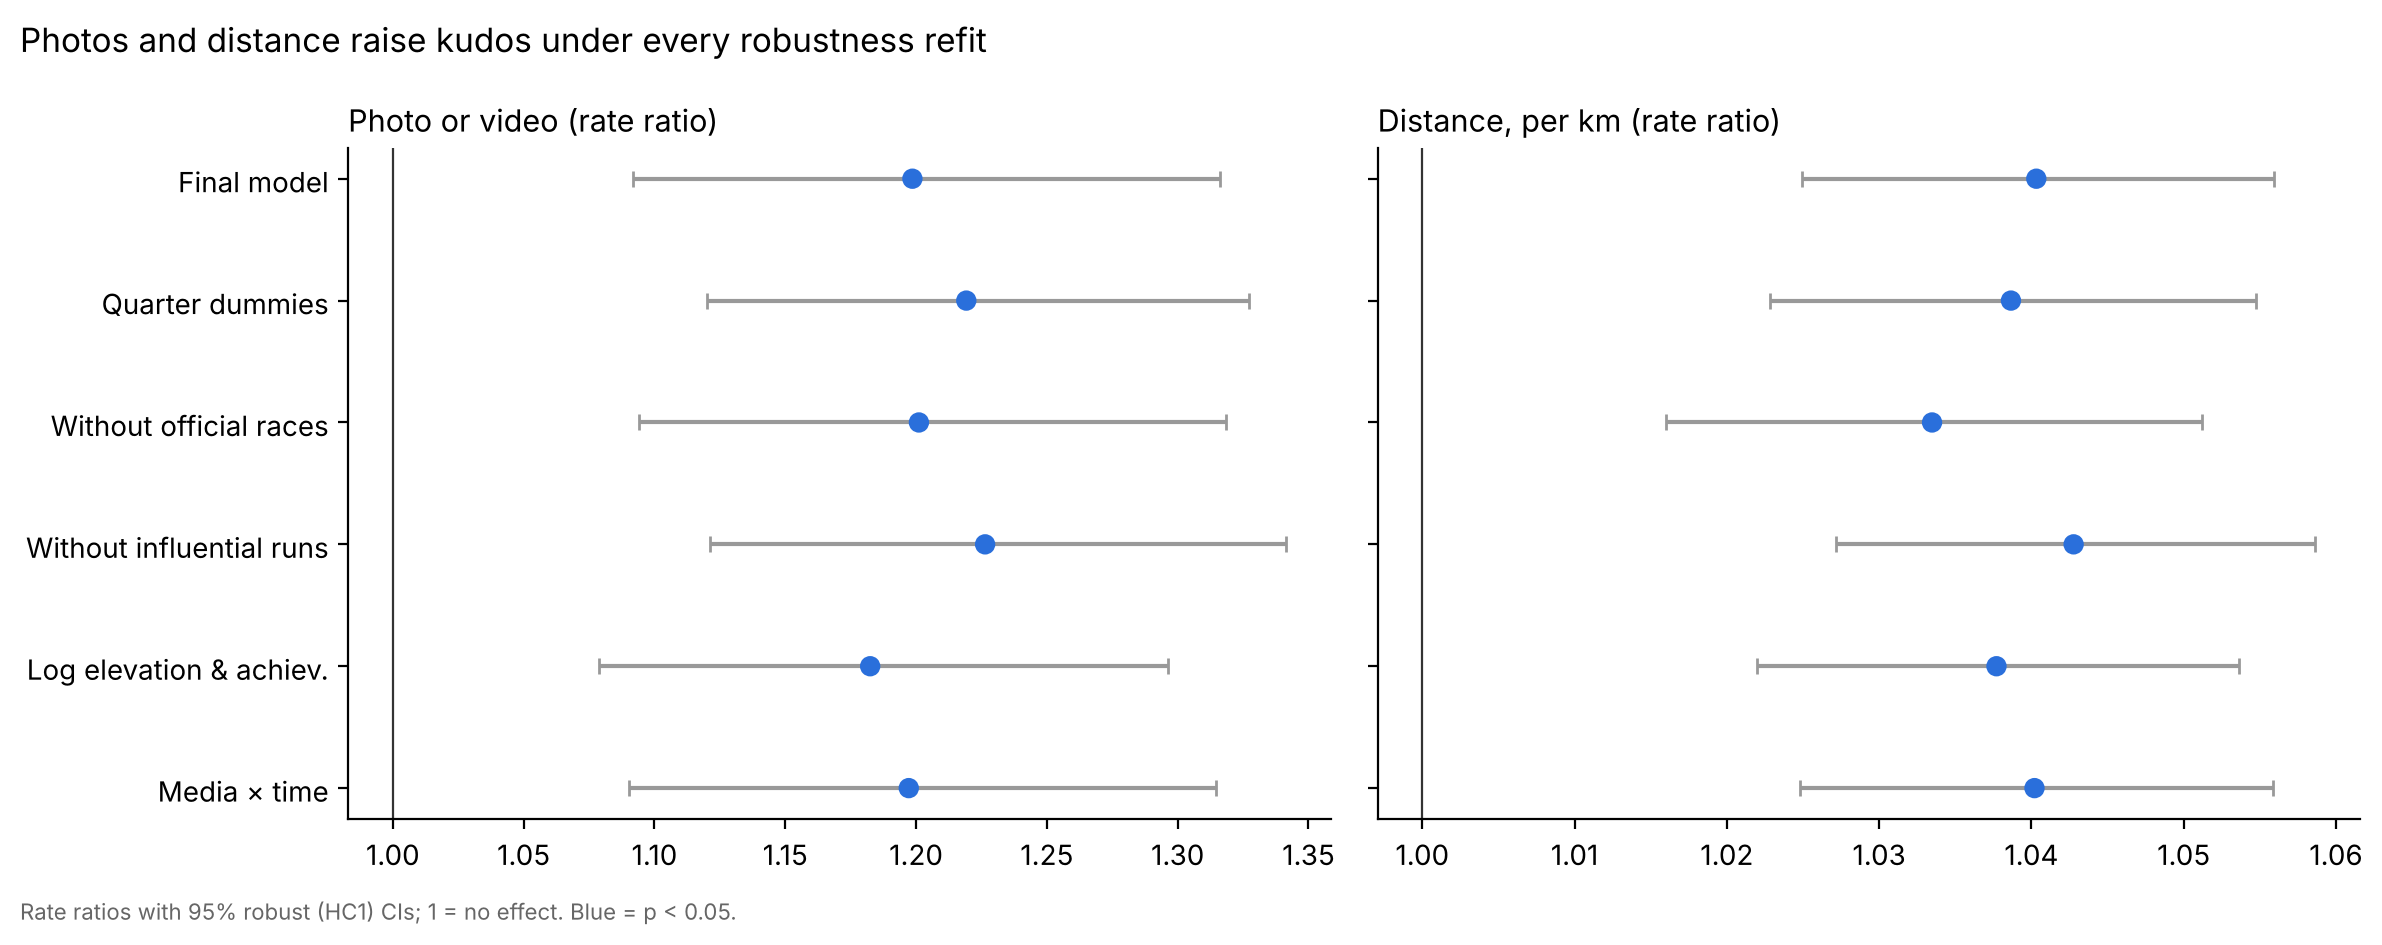

In [ ]:
nice_spec = list(specs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, var, title in [(axes[0], "has_media", "Photo or video (rate ratio)"),
                       (axes[1], "distance_km", "Distance, per km (rate ratio)")]:
    d = rob_long[rob_long["var"] == var].set_index("spec").reindex(nice_spec)
    y = np.arange(len(d))[::-1]
    sig = d["p"] < 0.05
    ax.errorbar(d["RR"], y, xerr=[d["RR"] - d["low"], d["high"] - d["RR"]],
                fmt="none", ecolor="#999999", elinewidth=1.5, capsize=3)
    ax.scatter(d["RR"], y, color=np.where(sig, "#2a6fdb", "#999999"), zorder=3, s=40)
    ax.axvline(1, color="#333333", linewidth=0.8)
    ax.set_yticks(y, d.index)
    ax.set_title(title, loc="left", fontsize=11)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.suptitle("Photos and distance raise kudos under every robustness refit",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, -0.02, "Rate ratios with 95% robust (HC1) CIs; 1 = no effect. Blue = p < 0.05.",
         fontsize=8, color="#666666")
plt.tight_layout(); plt.savefig("figures/robustness_forest.png", dpi=200, bbox_inches="tight"); plt.show()

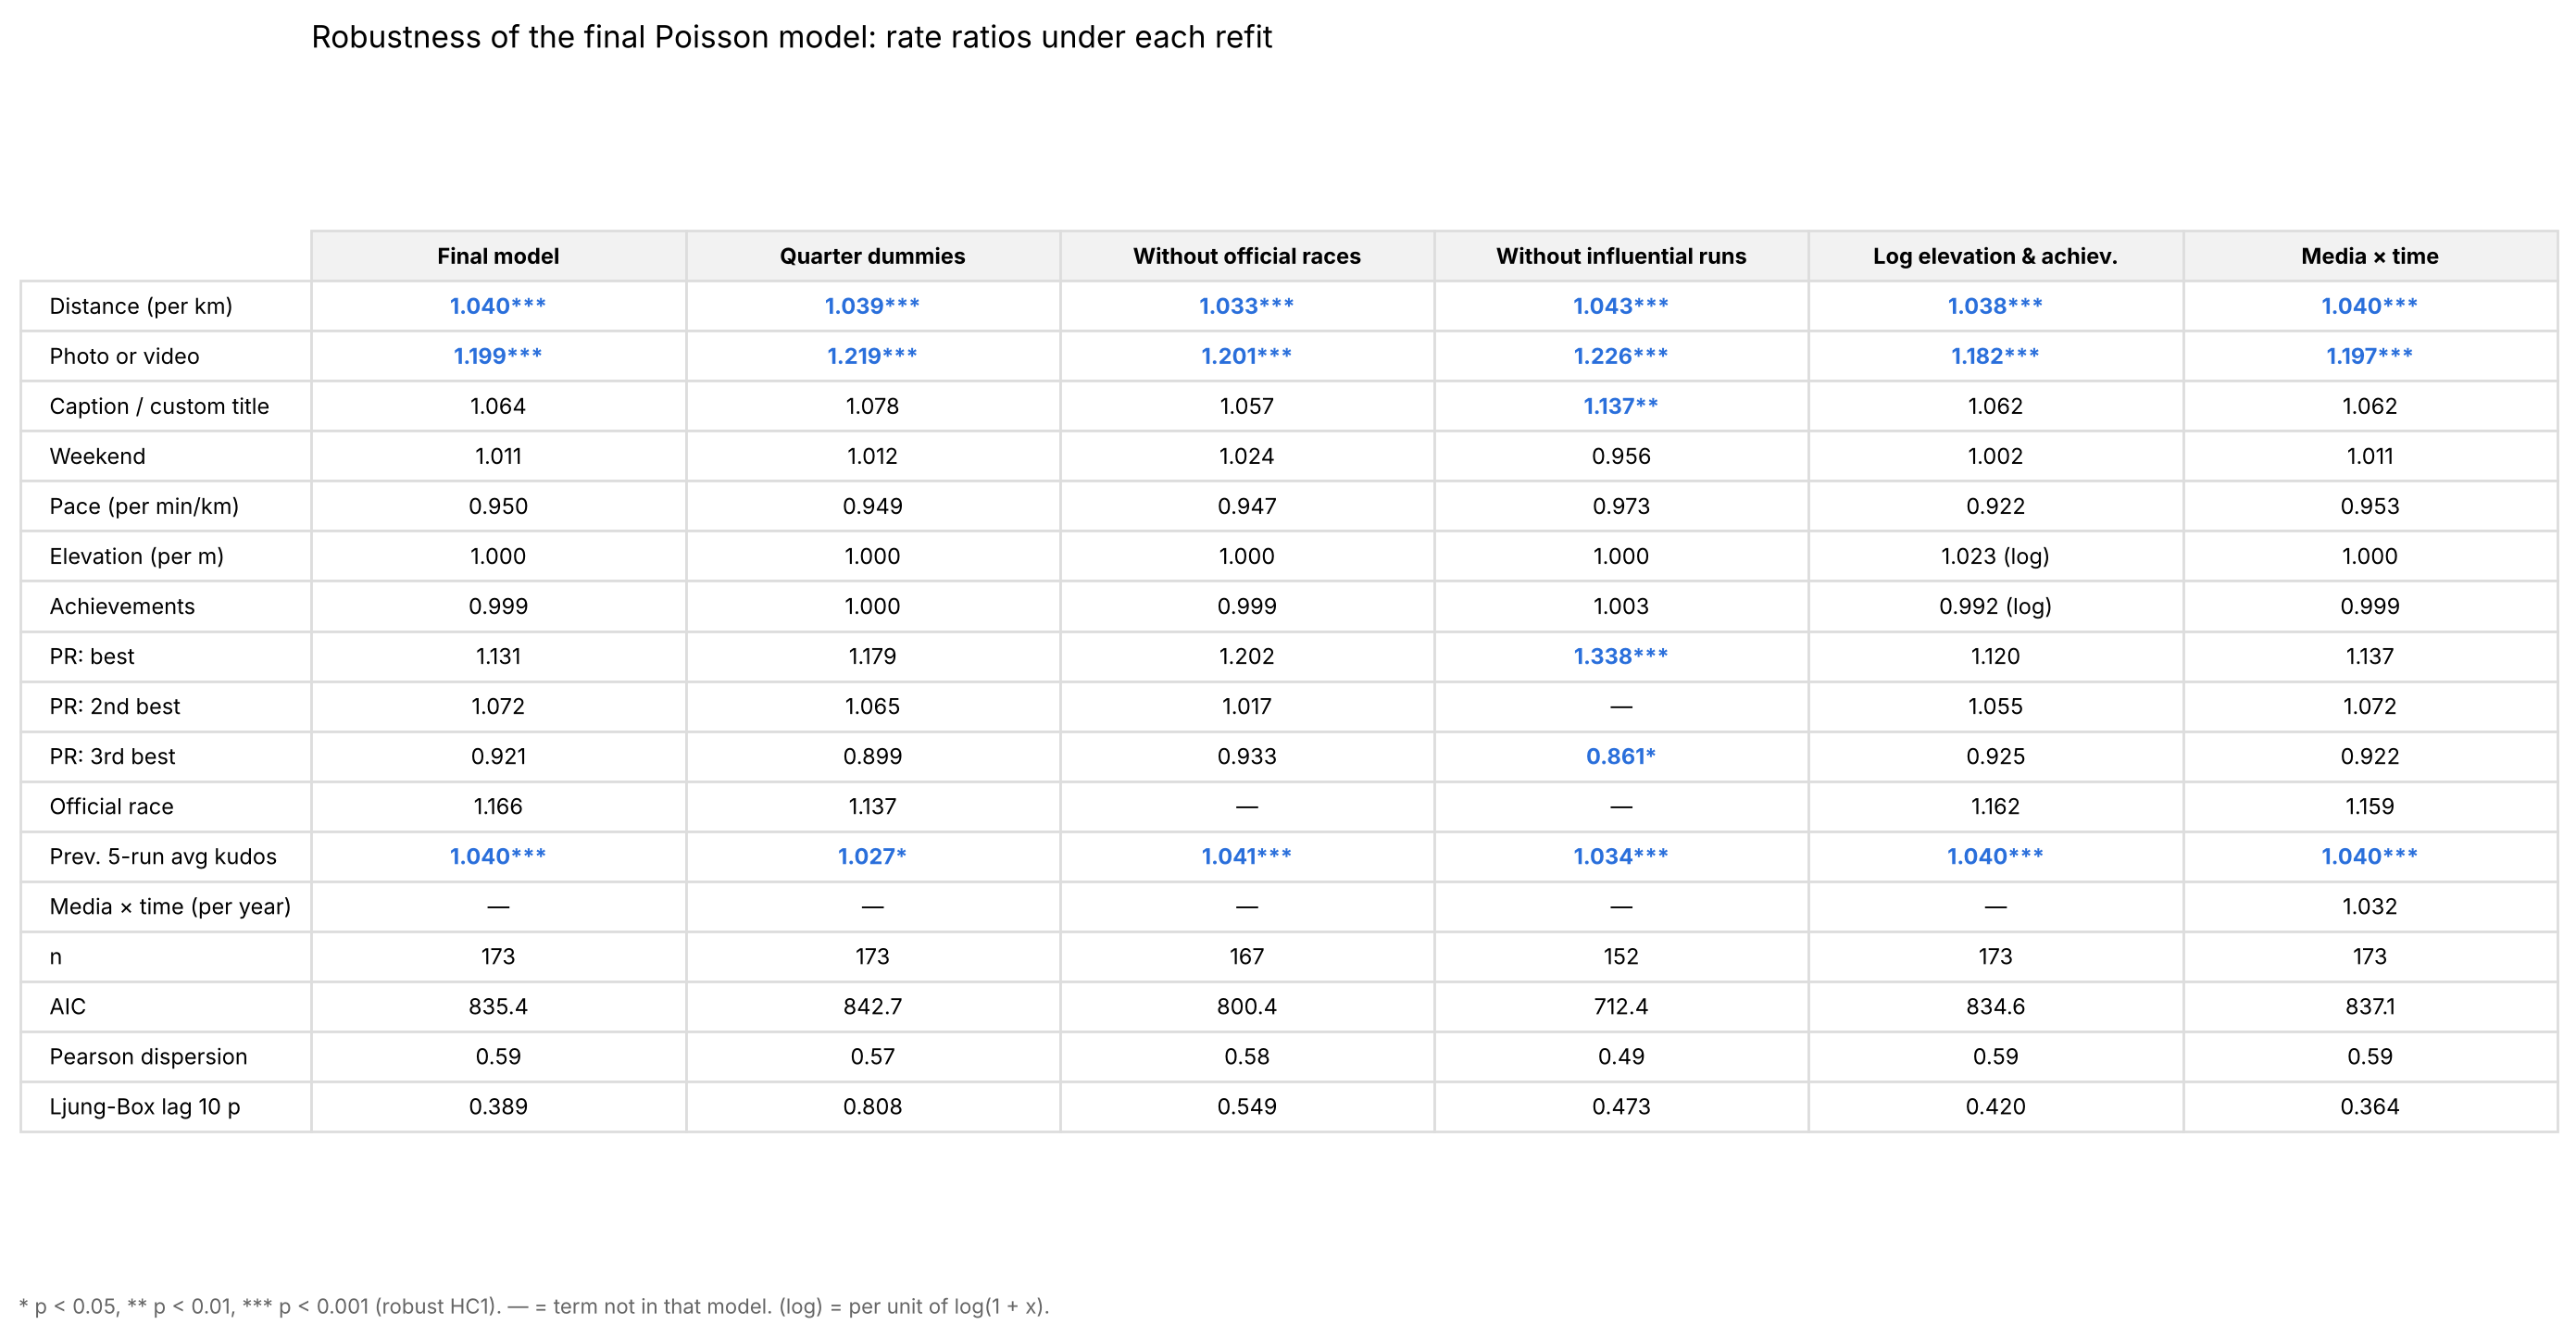

In [ ]:
nice_var = {"distance_km": "Distance (per km)", "has_media": "Photo or video", "has_custom_text": "Caption / custom title",
            "is_weekend": "Weekend", "pace_min_per_km": "Pace (per min/km)", "elevation_gain": "Elevation (per m)",
            "achievements_count": "Achievements", "pr_best": "PR: best", "pr_2nd": "PR: 2nd best",
            "pr_3rd": "PR: 3rd best", "official_race": "Official race", "prev5_kudos": "Prev. 5-run avg kudos",
            "has_media:t": "Media × time (per year)"}
show = rob_table.rename(index=nice_var)
fig, ax = plt.subplots(figsize=(14, 0.38 * (len(show) + 2)))
ax.axis("off")
tab = ax.table(cellText=show.values, rowLabels=show.index, colLabels=show.columns,
               cellLoc="center", rowLoc="left", loc="center")
tab.auto_set_font_size(False); tab.set_fontsize(8.5); tab.scale(1, 1.35)
for (r_i, c_i), cell in tab.get_celld().items():
    cell.set_edgecolor("#dddddd")
    if r_i == 0:
        cell.set_text_props(weight="bold"); cell.set_facecolor("#f2f2f2")
    if "*" in cell.get_text().get_text():
        cell.set_text_props(color="#2a6fdb", weight="bold")
ax.set_title("Robustness of the final Poisson model: rate ratios under each refit", loc="left", fontsize=12)
fig.text(0.01, 0.01, "* p < 0.05, ** p < 0.01, *** p < 0.001 (robust HC1). — = term not in that model. "
         "(log) = per unit of log(1 + x).", fontsize=8, color="#666666")
plt.tight_layout(); plt.savefig("figures/robustness_table.png", dpi=200, bbox_inches="tight"); plt.show()

### Interpretation: robustness refits

- **Photo or video (H1):** rate ratio between 1.18 and 1.23, significant in all six models.

- **Distance (H3):** rate ratio between 1.033 and 1.043 per km, significant in all six models.

- **The other variables** are not significant in any refit, except in the one without influential runs.

- **Without influential runs (152 runs):** this removes 21 runs, including all 6 races and all 8 second-best PR runs, so those two variables drop out. Custom text (1.14), best PR (1.34) and 3rd-best PR (0.86) become significant. We don't count these as findings, because they only show up in this one refit and the removed runs are the ones the model fit worst. Photos and distance don't change.

- **Quarter dummies:** higher AIC than the quadratic (842.7 vs 835.4) and the results barely change, so we keep the quadratic.

- **Log of elevation and achievements:** AIC 834.6 vs 835.4, almost the same, and no other result changes. We keep the original units because they are easier to explain.

- **Media × time:** rate ratio 1.03 per year, p = 0.54. The photo effect doesn't change over time, so we don't keep the interaction.

- **Residuals:** Ljung-Box p is above 0.36 in every refit, so the autocorrelation stays fixed. The Pearson dispersion is about 0.6, which means the classical standard errors are a bit too large, so we report the robust ones.

## 4. VIF check

We repeat the VIF check from Part 1 on the final model, now with `prev5_kudos`, which could be correlated with the time trend.

In [ ]:
def vif_table(model):
    X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=X.columns[1:], name="VIF")

vif_final = vif_table(rob_models["Final model"])
vif_log = vif_table(rob_models["Log elevation & achiev."])
display(pd.concat([vif_final.rename("VIF final"), vif_log.rename("VIF log version")], axis=1)
          .sort_values("VIF final", ascending=False).round(2))
print("Largest VIF in final model:", vif_final.idxmax(), round(vif_final.max(), 2))

,VIF final,VIF log version
distance_km,2.49,2.55
t,2.35,2.42
prev5_kudos,2.00,2.01
t_sq,2.00,1.99
pr_best,1.76,1.77
pace_min_per_km,1.75,1.75
elevation_gain,1.74,NaN
official_race,1.69,1.60
is_weekend,1.59,1.59
achievements_count,1.54,NaN


Largest VIF in final model: distance_km 2.49


### Interpretation: VIF

All VIFs are below 2.5 , well under the usual limit of 5. Adding `prev5_kudos`  raises the VIF of `t` from 1.82 to 2.35 and of `t_sq` from 1.25 to 2.00, since they all measure the audience, but these are still low. Collinearity is not a problem.

## 5. Final model

In [ ]:
final_model = rob_models["Final model"]
final_classic = smf.glm(FINAL_FORMULA, data=final_data, family=sm.families.Poisson()).fit()
final_predictors = [v.strip() for v in FINAL_FORMULA.split("~")[1].split("+")]

ci_f = final_model.conf_int()
final_rr = pd.DataFrame({
    "coef": final_model.params,
    "rate_ratio": np.exp(final_model.params),
    "RR_low_HC1": np.exp(ci_f[0]),
    "RR_high_HC1": np.exp(ci_f[1]),
    "p_robust_HC1": final_model.pvalues,
    "p_classic": final_classic.pvalues,
})
display(final_rr.round(4))
final_rr.round(4).to_csv("outputs/final_model_rate_ratios.csv")

print("LOCKED FINAL MODEL (Poisson, log link, robust HC1 SEs)")
print("  formula:   ", FINAL_FORMULA)
print("  predictors:", final_predictors)
print(f"  n = {int(final_model.nobs)}, AIC = {final_model.aic:.2f}, "
      f"Pearson dispersion = {final_model.pearson_chi2 / final_model.df_resid:.2f}")

,coef,rate_ratio,RR_low_HC1,RR_high_HC1,p_robust_HC1,p_classic
Intercept,1.9390,6.9518,4.0128,12.0435,0.0000,0.0000
t,0.1123,1.1189,1.0448,1.1981,0.0013,0.0264
t_sq,-0.2322,0.7928,0.7151,0.8790,0.0000,0.0012
distance_km,0.0395,1.0403,1.0249,1.0560,0.0000,0.0001
elevation_gain,-0.0002,0.9998,0.9992,1.0003,0.3986,0.5925
pace_min_per_km,-0.0511,0.9502,0.8738,1.0332,0.2317,0.3565
achievements_count,-0.0011,0.9989,0.9951,1.0027,0.5747,0.7370
pr_best,0.1233,1.1313,0.9457,1.3532,0.1773,0.2774
pr_2nd,0.0697,1.0722,0.9197,1.2500,0.3730,0.5806
pr_3rd,-0.0825,0.9208,0.8038,1.0549,0.2343,0.3706


LOCKED FINAL MODEL (Poisson, log link, robust HC1 SEs)
  formula:    kudos_count ~ t + t_sq + distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + official_race + has_media + has_custom_text + is_weekend + prev5_kudos
  predictors: ['t', 't_sq', 'distance_km', 'elevation_gain', 'pace_min_per_km', 'achievements_count', 'pr_best', 'pr_2nd', 'pr_3rd', 'official_race', 'has_media', 'has_custom_text', 'is_weekend', 'prev5_kudos']
  n = 173, AIC = 835.35, Pearson dispersion = 0.59


## Conclusion of Part 4

A **rate ratio** is how the model's coefficients are read in a Poisson model. It is exp(coef), and it tells you how much the expected number of kudos is multiplied when a variable goes up by 1, keeping everything else the same.
- Rate ratio = 1: no effect.
- Above 1: more kudos (1.20 means ×1.2, so 20% more).
- Below 1: fewer kudos (0.90 means ×0.9, so 10% fewer).

**Final model:** Poisson, log link, robust (HC1) standard errors, 173 runs:
`kudos_count ~ t + t_sq + distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + official_race + has_media + has_custom_text + is_weekend + prev5_kudos`

**Main results:**
- Photo or video: rate ratio 1.20, so about 20% more kudos.
- Distance: rate ratio 1.040 per km.
- The time trend and `prev5_kudos` are both significant.
- Not significant: custom text, weekend, pace, elevation, achievements, PRs.
- AIC = 835.35, Pearson dispersion = 0.59.

**Why this model:**
- Model D's residuals were autocorrelated, and adding `prev5_kudos` fixed it.
- Photos and distance stay significant in all five refits.
- The log versions and the interaction did not improve the model.
- All VIFs are below 2.5.

**Difference from Part 2:** the OLS model in Part 2 did not include `prev5_kudos`. As agreed in the project plan, Part 2 stays as it is. Both models find the same two effects: OLS gives +1.7 kudos for a photo and +0.43 per km, and the final Poisson model gives about +20% and +4% per km.


# Part 5: Logistic check and synthesis

In this part we check if the same variables also predict a "breakout" run. Then we put all the results together in one H1 to H7 table and give recommendations.

**Breakout run:** `breakout` = 1 if a run gets more kudos than the median of the previous 10 runs, 0 otherwise.
- Each run is compared with the runs just before it, so the growth in followers is already taken into account.
- That's why the logistic model only uses the run characteristics from the final model. We leave out `t`, `t_sq` and `prev5_kudos`, since the outcome already compares each run with recent ones.
- The first 10 runs don't have 10 earlier runs, so we have 168 runs.

**Method:** logistic regression with a 70/30 train/test split (stratified, `random_state = 67` as in Part 1). We report odds ratios, the confusion matrix, accuracy, sensitivity, specificity and ROC/AUC on the test set.

**Outputs:** `outputs/logit_odds_ratios.csv`, `outputs/hypotheses_results.csv`, `figures/logit_confusion_roc.png`, `figures/hypotheses_table.png`.

## 1. Breakout outcome

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# shift(1) so the run itself is not included in the median
runs["prev10_median"] = runs["kudos_count"].shift(1).rolling(10).median()
logit_df = runs.dropna(subset=["prev10_median"]).copy()
logit_df["breakout"] = (logit_df["kudos_count"] > logit_df["prev10_median"]).astype(int)

print("Runs with a 10-run history:", len(logit_df))
print("Breakout runs:", logit_df["breakout"].sum(), f"({logit_df['breakout'].mean():.0%})")
display(logit_df.groupby("breakout")[["kudos_count", "prev10_median", "distance_km", "has_media",
                                      "has_custom_text", "is_weekend", "official_race"]].mean().round(2))

Runs with a 10-run history: 168
Breakout runs: 80 (48%)


,kudos_count,prev10_median,distance_km,has_media,has_custom_text,is_weekend,official_race
breakout,,,,,,,
0,8.12,10.29,6.52,0.17,0.59,0.20,0.00
1,12.49,9.28,8.93,0.54,0.80,0.49,0.08


## 2. Train/test split and predictors

Before fitting, we check each yes/no variable in the training set. If all runs in one group are breakouts (or none are), the model can't estimate that variable (perfect separation), so we drop it.

In [ ]:
audience_controls = {"t", "t_sq", "prev5_kudos"}
logit_terms = [v for v in final_predictors if v not in audience_controls]

train, test = train_test_split(logit_df, test_size=0.3, stratify=logit_df["breakout"], random_state=67)
print(f"Train: {len(train)} runs ({train['breakout'].mean():.0%} breakouts)   "
      f"Test: {len(test)} runs ({test['breakout'].mean():.0%} breakouts)")

dropped = []
for v in logit_terms:
    if v in train.columns and set(train[v].unique()) <= {0, 1}:
        tab = pd.crosstab(train[v], train["breakout"])
        if tab.shape != (2, 2) or (tab.values == 0).any():
            dropped.append(v)
            print(f"\nDropped {v} (perfect separation in the training set):")
            display(tab)
logit_terms_used = [v for v in logit_terms if v not in dropped]
logit_formula = "breakout ~ " + " + ".join(logit_terms_used)
print("\nLogistic formula:", logit_formula)
print(f"Events per predictor (training): {min(train['breakout'].sum(), (1 - train['breakout']).sum()) / len(logit_terms_used):.1f}")

Train: 117 runs (48% breakouts)   Test: 51 runs (47% breakouts)



Dropped official_race (perfect separation in the training set):


breakout,0,1
official_race,,
0,61,52
1,0,4



Logistic formula: breakout ~ distance_km + elevation_gain + pace_min_per_km + achievements_count + pr_best + pr_2nd + pr_3rd + has_media + has_custom_text + is_weekend
Events per predictor (training): 5.6


## 3. Logistic model and odds ratios

The odds ratio is exp(coef). It shows how the odds of a breakout change when the variable goes up by 1, keeping the others constant. OR = 1.5 means 50% higher odds, and OR = 1 means no effect.

In [ ]:
logit = smf.logit(logit_formula, data=train).fit(disp=0)
print(logit.summary())

ci_l = logit.conf_int()
or_table = pd.DataFrame({
    "coef": logit.params,
    "odds_ratio": np.exp(logit.params),
    "OR_low": np.exp(ci_l[0]),
    "OR_high": np.exp(ci_l[1]),
    "p_value": logit.pvalues,
}).drop(index="Intercept")
display(or_table.round(3))
or_table.round(4).to_csv("outputs/logit_odds_ratios.csv")

                           Logit Regression Results                           
Dep. Variable:               breakout   No. Observations:                  117
Model:                          Logit   Df Residuals:                      106
Method:                           MLE   Df Model:                           10
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                  0.1782
Time:                        12:48:14   Log-Likelihood:                -66.557
converged:                       True   LL-Null:                       -80.991
Covariance Type:            nonrobust   LLR p-value:                  0.001309
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.1564      2.981      0.388      0.698      -4.686       6.999
distance_km            0.1973      0.101      1.961      0.050    8.56e-05       0.394
elevation_gain      

,coef,odds_ratio,OR_low,OR_high,p_value
distance_km,0.197,1.218,1.000,1.484,0.050
elevation_gain,0.001,1.001,0.993,1.009,0.771
pace_min_per_km,-0.548,0.578,0.232,1.444,0.241
achievements_count,-0.004,0.996,0.946,1.048,0.871
pr_best,0.976,2.653,0.371,18.951,0.331
pr_2nd,0.040,1.040,0.105,10.322,0.973
pr_3rd,-0.639,0.528,0.122,2.287,0.393
has_media,1.288,3.626,1.330,9.888,0.012
has_custom_text,0.651,1.918,0.705,5.220,0.202
is_weekend,0.031,1.032,0.358,2.975,0.954


## 4. Test set performance

A run is predicted as a breakout if its predicted probability is 0.5 or more. We compare accuracy with a baseline that always guesses the most common class.

,value
Accuracy,0.765
Baseline accuracy (majority class),0.529
Sensitivity (breakouts caught),0.625
Specificity (non-breakouts caught),0.889
Precision (predicted breakouts that were real),0.833
AUC (test),0.821
AUC (train),0.779


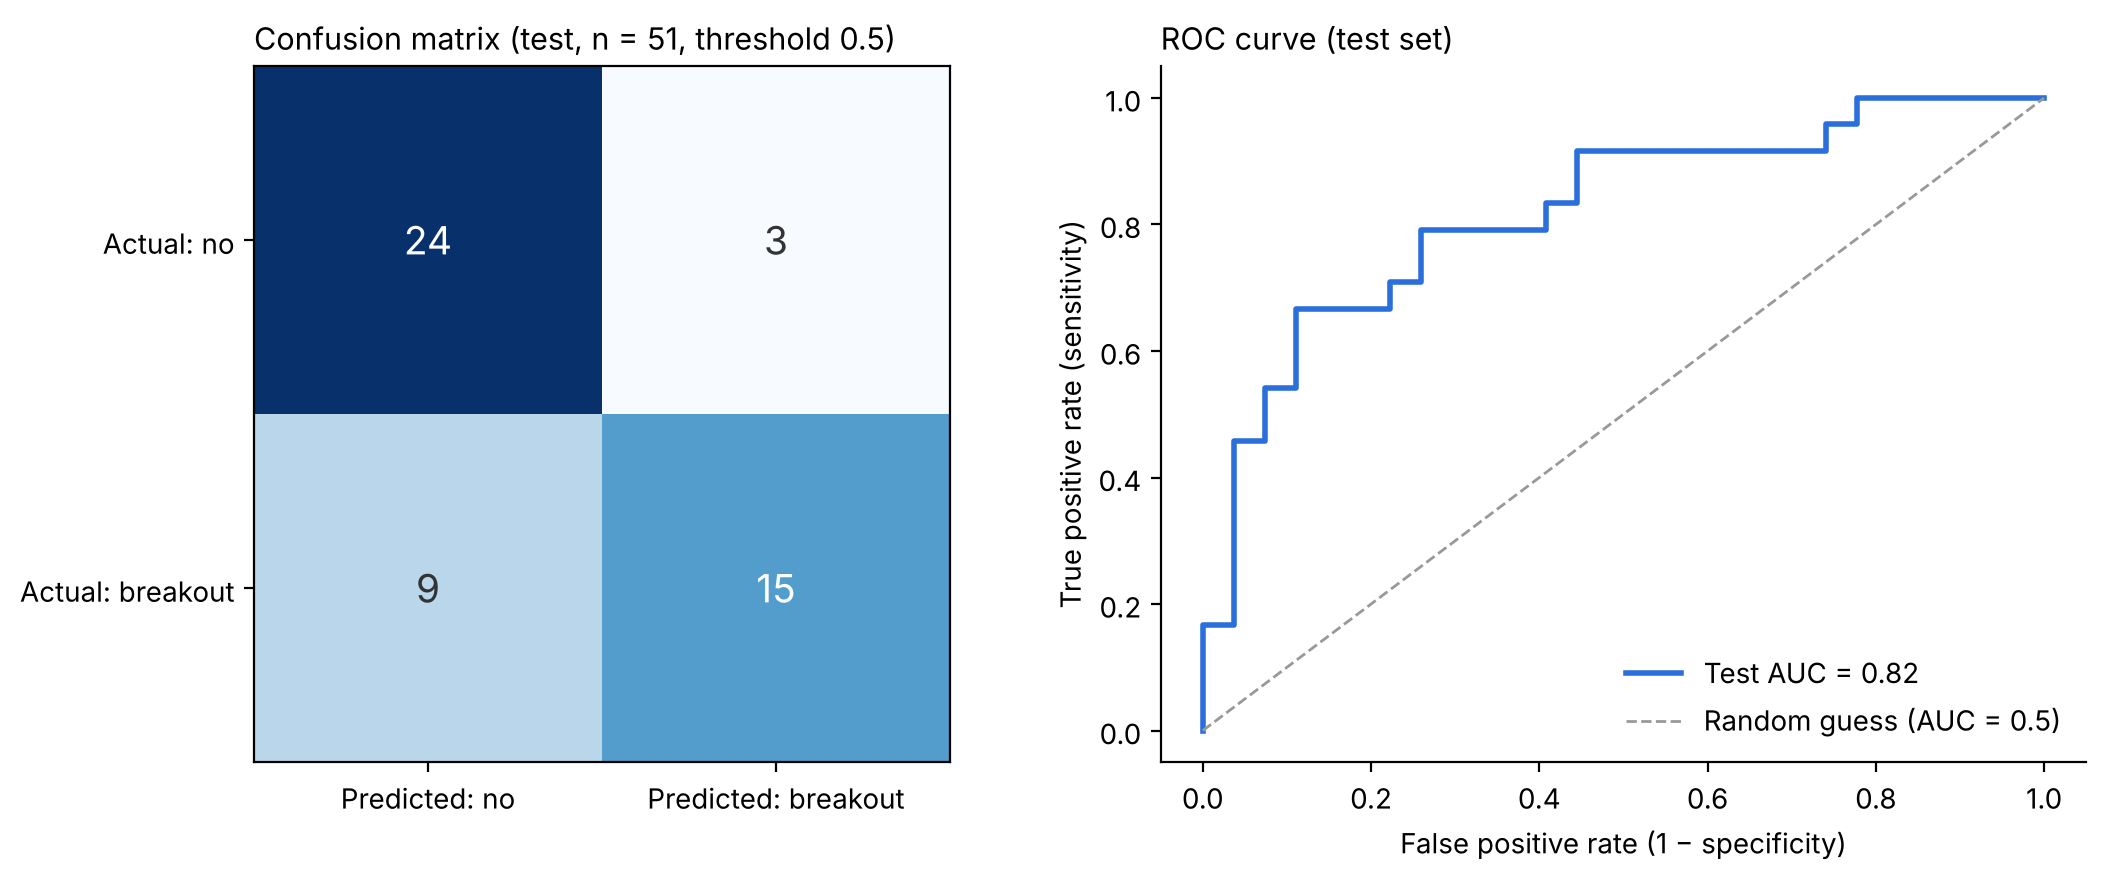

In [ ]:
p_test = logit.predict(test)
pred_test = (p_test >= 0.5).astype(int)
y_test = test["breakout"]

cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
auc_test = roc_auc_score(y_test, p_test)
auc_train = roc_auc_score(train["breakout"], logit.predict(train))
metrics = pd.Series({
    "Accuracy": (tp + tn) / cm.sum(),
    "Baseline accuracy (majority class)": max(y_test.mean(), 1 - y_test.mean()),
    "Sensitivity (breakouts caught)": tp / (tp + fn),
    "Specificity (non-breakouts caught)": tn / (tn + fp),
    "Precision (predicted breakouts that were real)": tp / (tp + fp) if (tp + fp) else np.nan,
    "AUC (test)": auc_test,
    "AUC (train)": auc_train,
})
display(metrics.round(3).to_frame("value"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "#333333")
ax.set_xticks([0, 1], ["Predicted: no", "Predicted: breakout"])
ax.set_yticks([0, 1], ["Actual: no", "Actual: breakout"])
ax.set_title(f"Confusion matrix (test, n = {len(test)}, threshold 0.5)", loc="left", fontsize=11)

ax = axes[1]
fpr, tpr, _ = roc_curve(y_test, p_test)
ax.plot(fpr, tpr, color="#2a6fdb", linewidth=2, label=f"Test AUC = {auc_test:.2f}")
ax.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1, label="Random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate (1 − specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curve (test set)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.savefig("figures/logit_confusion_roc.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# time-based split: train on the oldest 70% of runs, test on the newest 30%
by_date = logit_df.sort_values("activity_date")
cut = int(len(by_date) * 0.7)
train_t, test_t = by_date.iloc[:cut], by_date.iloc[cut:]
try:
    logit_t = smf.logit(logit_formula, data=train_t).fit(disp=0)
    print(f"Chronological split: train {len(train_t)} runs (to {train_t['activity_date'].max().date()}), "
          f"test {len(test_t)} runs; test AUC = {roc_auc_score(test_t['breakout'], logit_t.predict(test_t)):.3f}")
except Exception as e:
    print("Chronological split could not be fitted:", e)

Chronological split: train 117 runs (to 2026-02-13), test 51 runs; test AUC = 0.713


### Interpretation: logistic check

- **Outcome:** 80 of the 168 runs are breakouts, so the two groups are about the same size. Breakout runs are longer, more often have a photo and are more often on a weekend.

- **Official race dropped:** all 4 races in the training set were breakouts, so the model can't estimate this variable.

- **Odds ratios:** a photo or video multiplies the odds of a breakout by 3.6 . Each extra km multiplies the odds by 1.22 . This matches the Poisson model. Weekend has no effect once distance is included . The other variables are not significant, and the PR intervals are very wide because the groups are small.

- **Test set (51 runs):** accuracy 0.76 vs 0.53 for the baseline. The model finds 62% of breakouts and 89% of non breakouts, and 83% of predicted breakouts were real. AUC is 0.82 on the test set and 0.78 on the training set, so the model separates breakout runs from the others well. The test AUC being higher is probably luck with a small test set.

- **Time-based split:** training on runs up to February 2026 and testing on the later runs gives an AUC of 0.71. This is more realistic for predicting future runs, and still well above 0.5.

- **Limits:** the test set is small, so one or two runs can change accuracy by 2 to 4 points. There are 5.6 events per predictor in the training set, below the usual 10, so the coefficients are less stable than in the Poisson model. That's why we only use the logistic model as a check.

## 5. H1 to H7 results

One row per hypothesis, with the results from each part:
- **t-test (Part 1):** simple comparison without controls.
- **OLS (Part 2):** coefficient, robust p value.
- **Poisson D (Part 3):** rate ratio, robust p value.
- **Final model (Part 4):** rate ratio, robust p value. This is the main result.
- **Robust:** in how many of the 5 refits from Part 4 the effect stays significant in the expected direction.
- **Logistic (Part 5):** odds ratio of a breakout.

**Verdict:**
- *Supported*: significant in the expected direction in the final model and in all refits.
- *Partly supported*: significant in the final model but not in every refit.
- *Not supported once controls are added*: significant in the t-test only.
- *Opposite direction*: significant in the final model, but the other way.
- *Not supported*: not significant in the final model.

For H7, the three PR dummies are tested together with a likelihood ratio test.

In [ ]:
hyps = [("H1 (media)", "has_media", +1), ("H2 (achievements)", "achievements_count", +1),
        ("H3 (distance)", "distance_km", +1), ("H4 (custom text)", "has_custom_text", +1),
        ("H5 (speed)", "pace_min_per_km", -1),   # lower pace = faster, so expected RR < 1
        ("H6 (weekend)", "is_weekend", +1), ("H7 (PR)", "pr_best", +1)]

ttests = summary.reset_index(drop=True)   # t-test table from Part 1
refits = [s for s in rob_models if s != "Final model"]

# H7: joint LR test of the three PR dummies
no_pr = smf.glm(FINAL_FORMULA.replace(" + pr_best + pr_2nd + pr_3rd", ""), data=final_data,
                family=sm.families.Poisson()).fit()
lr_pr, df_pr, p_pr = lr_test(no_pr, final_classic)

def fmt(x, p):
    return f"{x:.3f}{stars(p)} (p={p:.3f})"

rows = []
for i, (h, var, sign) in enumerate(hyps):
    t_row = ttests.loc[i]
    t_dir = np.sign(t_row["mean_kudos_yes"] - t_row["mean_kudos_no"])
    t_ok = (t_row["p_value"] < 0.05) and t_dir > 0
    b_f, p_f = final_model.params[var], final_model.pvalues[var]
    final_ok = (p_f < 0.05) and np.sign(b_f) == sign
    n_ok = 0
    for s in refits:
        hit = lookup(rob_models[s], var)
        if hit and hit[2] < 0.05 and np.sign(hit[1]) == sign:
            n_ok += 1
    if var in logit.params.index:
        logit_txt = fmt(np.exp(logit.params[var]), logit.pvalues[var])
    else:
        logit_txt = "dropped"
    if final_ok and n_ok == len(refits):
        verdict = "Supported"
    elif final_ok:
        verdict = "Partly supported (not robust)"
    elif p_f < 0.05:
        verdict = "Opposite direction (significant)"
    elif t_ok:
        verdict = "Not supported once controls are added"
    else:
        verdict = "Not supported"
    rows.append({
        "Hypothesis": h, "Variable": var,
        "t-test p (Part 1)": f"{t_row['p_value']:.3f}",
        "OLS coef (Part 2)": fmt(coef_table.loc[var, "coef"], coef_table.loc[var, "p_value_HC3"]),
        "Poisson D RR (Part 3)": fmt(rr.loc[var, "rate_ratio"], rr.loc[var, "p_robust_HC1"]),
        "Final model RR (Part 4)": fmt(np.exp(b_f), p_f),
        f"Robust (of {len(refits)} refits)": f"{n_ok}/{len(refits)}",
        "Logistic OR (Part 5)": logit_txt,
        "Verdict": verdict,
    })

hyp_table = pd.DataFrame(rows).set_index("Hypothesis")
display(hyp_table)
print(f"H7 joint LR test (pr_best, pr_2nd, pr_3rd = 0) in the final model: LR = {lr_pr:.2f}, df = {df_pr}, p = {p_pr:.3f}")
print("H5: pace is in min/km, so a rate ratio below 1 means faster runs get more kudos.")
hyp_table.to_csv("outputs/hypotheses_results.csv")

,Variable,t-test p (Part 1),OLS coef (Part 2),Poisson D RR (Part 3),Final model RR (Part 4),Robust (of 5 refits),Logistic OR (Part 5),Verdict
Hypothesis,,,,,,,,
H1 (media),has_media,0.001,1.749** (p=0.001),1.178*** (p=0.001),1.199*** (p=0.000),5/5,3.626* (p=0.012),Supported
H2 (achievements),achievements_count,0.619,-0.020 (p=0.463),0.998 (p=0.420),0.999 (p=0.575),0/5,0.996 (p=0.871),Not supported
H3 (distance),distance_km,0.000,0.431*** (p=0.000),1.042*** (p=0.000),1.040*** (p=0.000),5/5,1.218* (p=0.050),Supported
H4 (custom text),has_custom_text,0.052,0.746 (p=0.167),1.083 (p=0.145),1.064 (p=0.234),1/5,1.918 (p=0.202),Not supported
H5 (speed),pace_min_per_km,0.855,-0.443 (p=0.376),0.938 (p=0.116),0.950 (p=0.232),0/5,0.578 (p=0.241),Not supported
H6 (weekend),is_weekend,0.001,0.149 (p=0.790),1.022 (p=0.655),1.011 (p=0.816),0/5,1.032 (p=0.954),Not supported once controls are added
H7 (PR),pr_best,0.374,1.569 (p=0.173),1.083 (p=0.454),1.131 (p=0.177),1/5,2.653 (p=0.331),Not supported


H7 joint LR test (pr_best, pr_2nd, pr_3rd = 0) in the final model: LR = 2.97, df = 3, p = 0.396
H5: pace is in min/km, so a rate ratio below 1 means faster runs get more kudos.


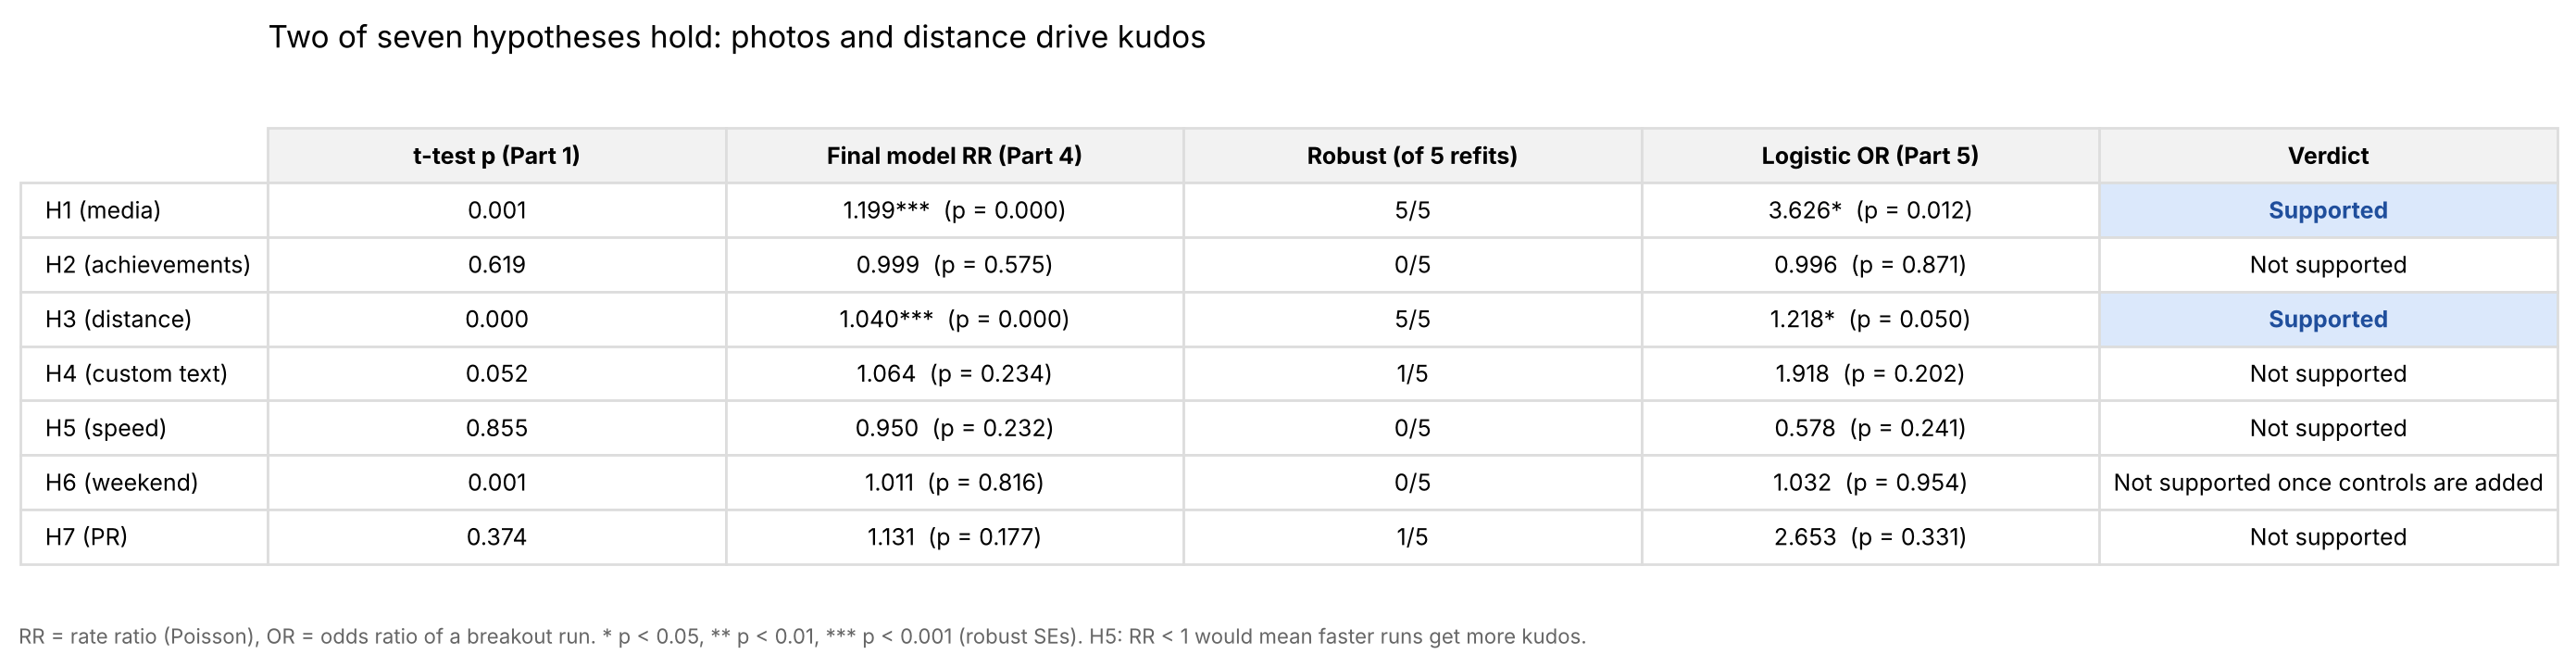

In [ ]:
slide_cols = ["t-test p (Part 1)", "Final model RR (Part 4)", f"Robust (of {len(refits)} refits)",
              "Logistic OR (Part 5)", "Verdict"]
show = hyp_table[slide_cols].copy()
for c in ["Final model RR (Part 4)", "Logistic OR (Part 5)"]:
    show[c] = show[c].str.replace(r" \(p=", "  (p = ", regex=True)
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.axis("off")
tab = ax.table(cellText=show.values, rowLabels=show.index, colLabels=show.columns,
               cellLoc="center", rowLoc="left", loc="center")
tab.auto_set_font_size(False); tab.set_fontsize(9); tab.scale(1, 1.6)
for (r_i, c_i), cell in tab.get_celld().items():
    cell.set_edgecolor("#dddddd")
    if r_i == 0:
        cell.set_text_props(weight="bold"); cell.set_facecolor("#f2f2f2")
    txt = cell.get_text().get_text()
    if txt == "Supported":
        cell.set_facecolor("#dbe8fb"); cell.set_text_props(weight="bold", color="#1f4e9c")
    elif txt.startswith("Partly"):
        cell.set_facecolor("#f3f3f3")
ax.set_title("Two of seven hypotheses hold: photos and distance drive kudos", loc="left", fontsize=12)
fig.text(0.01, 0.02, "RR = rate ratio (Poisson), OR = odds ratio of a breakout run. * p < 0.05, ** p < 0.01, *** p < 0.001 "
         "(robust SEs). H5: RR < 1 would mean faster runs get more kudos.", fontsize=8, color="#666666")
plt.tight_layout(); plt.savefig("figures/hypotheses_table.png", dpi=200, bbox_inches="tight"); plt.show()

### Interpretation: H1 to H7

- **H1 (media) - supported.** A photo or video gives about 20% more kudos in every refit, and multiplies the odds of a breakout by 3.6.
- **H3 (distance) - supported.** Each extra km gives about 4% more kudos  in every refit. A 10 km run gets about 22% more kudos than a 5 km run . Distance also raises the odds of a breakout, 1.22 per km.
- **H6 (weekend) - not supported once controls are added.** Weekend runs get more kudos in the t test , but that's because they are longer 10.2 vs 6.2 km. With distance in the model, the effect disappears.
- **H4 (custom text) - not supported.** This has a small positive effect but not significant. It's only significant in the refit without influential runs, and the t test was borderline.
- **H7 (PR) - not supported.** The three PR dummies together are not significant. Best PR is only significant without influential runs. The PR groups are small, so we can't rule out a small effect.
- **H2 (achievements) and H5 (speed) - not supported.** No effect in any model achievements RR 0.999, p = 0.58; pace RR 0.95, p = 0.23.

## 6. Recommendations


1. **Add a photo or video to every post.** It gives about 20% more kudos (around 2 more on a typical 10-kudo run) and is the easiest thing to change.
2. **Longer runs get more kudos**, about 4% per km. A 10 km run gets about 22% more than a 5 km run. Long runs are worth posting with a photo, but it's not a reason to run further.
3. **Posting on the weekend doesn't help by itself.** Weekend runs only get more kudos because they are longer.
4. **PRs, achievements, pace and captions don't make a clear difference** once distance, photos and the audience are taken into account.
5. **The audience matters most.** The time trend and the previous-5-runs average are strong predictors, so kudos depend a lot on how many followers are active. Growing the follower base probably matters more than any single post, but we couldn't test this without follower counts.

**Limitations:** one runner and 178 runs, so this is a case study. The data is observational, so the photo effect may partly come from photos being taken on nicer or more special runs. We don't have follower counts, so we use time and recent kudos instead.Strava only shows the current number, not what it was when each run was posted. There are only 6 official races, so the race effect is uncertain.